In [1]:
# =============================================================================
# LIBRERÍAS
# =============================================================================
import re
import warnings
from dataclasses import dataclass
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.gridspec import GridSpec
import seaborn as sns
import ipywidgets as widgets
from scipy import stats
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
# Gradientes de color sobre filas sin datos válidos (sensor descartado): aviso inofensivo de pandas
warnings.filterwarnings("ignore", message="All-NaN slice encountered")
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)

In [ ]:
# =============================================================================
# Configuracion
# =============================================================================
valid_ranges = {
    "conductivity": (0, 5), "temperature": (10, 25), "pH": (3, 9),
    "radiation": (0, 1000), "moisture": (0, 100), "airTemperature": (10, 50),
    "airHumidity": (20, 100)
}

variables_mapping = {
    "top_conductivity_20cm": "conductivity",
    "medium_conductivity_40cm": "conductivity",
    "bottom_conductivity_60cm": "conductivity",
    "top_ph_20cm": "pH", "medium_ph_40cm": "pH", "bottom_ph_60cm": "pH",
    "top_temperature_20cm": "temperature", "medium_temperature_40cm": "temperature", "bottom_temperature_60cm": "temperature",
    "top_moisture_20cm": "moisture", "medium_moisture_40cm": "moisture", "bottom_moisture_60cm": "moisture",
    "air_temperature": "airTemperature",
    "air_humidity": "airHumidity",
    "radiation": "radiation",
    "ECpw 20": "conductivity",
    "ECpw 41": "conductivity",
    "ECpw 66": "conductivity"
}

max_change = {
    "conductivity": 0.8,
    "temperature": 1,
    "pH": 0.5,
    "radiation": 200,
    "moisture": 10,
    "airTemperature": 6,
    "airHumidity": 25
}

FLAGS = {
    0: "Normal",
    1: "Anomalía física",
    2: "Anomalía histórica",
    3: "Spike aislado",
    4: "Cambio brusco",
    5: "Outlier MAD",
    6: "Anomalía multivariable",
    7: "Valor interpolado"
}

var_nosel = ["lat", "lon",
"conductivity_est_20",
"conductivity_est_40",
"conductivity_est_60",
"cultivo_reentrenamiento",
"finca_cropx", "cropx_sheet"]

Mod2_tom = ['medium_conductivity_40cm', 'medium_temperature_40cm', 'medium_moisture_40cm']

In [ ]:
# =============================================================================
# PARÁMETROS - rutas, fincas, fechas y umbrales
# =============================================================================
@dataclass(frozen=True)
class Finca:
    nombre: str
    fecha_inicio: str            # inicio del ciclo del cultivo en ESTA finca (paso 1)
    fecha_fin: str               # fin del ciclo del cultivo en ESTA finca
    rangos: dict | None = None   # {"Etapa": (inicio, fin)} propios de la finca (pasos 6 y 9)
                                 # None -> el ciclo se divide en N_RANGOS_AUTO tramos iguales


# --- Fincas a analizar: cada una con su ciclo y sus etapas ---
# Fechas sin hora en `fecha_fin` o en el fin de un rango incluyen todo ese día.
# Ciclos confirmados del cultivo. `rangos=None` divide cada ciclo en N_RANGOS_AUTO tramos iguales
FINCAS = [
    Finca(
        nombre="La_Orquidea", # NOTE: Agregar info de todo el año. Empezaron desde octubre.
        fecha_inicio="2025-11-24",
        fecha_fin="2026-05-21",
        rangos={
            #NOTE: Agregar nuevo rango. "Descanso"
            "Pre-siembra": ("2025-11-24", "2025-12-8"),
            "Vegetativa": ("2025-12-09", "2026-01-11"),
            "Floración":  ("2026-01-12", "2026-03-9"),
            "Cosecha":    ("2026-03-10", "2026-05-21")
        },
    ),
    Finca(
        nombre="Venecia",
        fecha_inicio="2026-05-5",
        fecha_fin="2026-10-19",
        rangos={
            "Pre-siembra": ("2026-05-5", "2026-05-20"),
            "Vegetativa": ("2026-05-21", "2026-06-20"),
            "Floración":  ("2026-06-21", "2026-08-26"),
            "Cosecha":    ("2026-08-27", "2026-10-19")
        },
    ),
    Finca(
        nombre="Puerto_Arturo",
        fecha_inicio="2026-02-06",
        fecha_fin="2026-09-01",
        rangos={
            "Pre-siembra": ("2026-02-06", "2026-02-09"),
            "Vegetativa": ("2026-02-10", "2026-03-21"),
            "Floración":  ("2026-03-22", "2026-06-14"),
            "Cosecha":    ("2026-06-15", "2026-09-01")
        },
    )
]
# Si las etapas usan los mismos nombres en todas las fincas, el paso 6 las compara entre fincas.
FINCAS_POR_NOMBRE = {f.nombre: f for f in FINCAS}
FINCAS_COMPARAR = ("La_Orquidea", "Venecia")   # paso 7

# ===========================
#       RUTAS
# ===========================
DIR_BASE = Path.cwd()
#Carpeta donde están los datos
DIR_DATOS = Path(R"D:\Estudio\OneDrive - Universidad de Antioquia\Estudio\PAI\Nuevos-Modelos-Paulina\Datos")

DIR_SALIDA = DIR_BASE / "outputs" / "EDA_telemetria_fija"
TIPO_TELEMETRIA = "fija"
RANGO_ARCHIVOS = "2024-01-01_to_2026-10-19" # NOTE: Nombre de datos aparece con este sufijo.
COL_TIEMPO = "timestamp" # Nombre de columna de tiempo
COLUMNAS_METADATOS = ["departamento", "municipio", "tipo", "nombre"]


### Cargar telemetria Fija de TODAS las fincas

In [4]:
path_datos_telemetria_fija = {finca.nombre: DIR_DATOS / finca.nombre /
                               f"telemetria_{TIPO_TELEMETRIA}_{finca.nombre}_{RANGO_ARCHIVOS}.xlsx" 
                               for finca in FINCAS}

BD_RAW_FIJA_FINCAS = {finca.nombre: pd.read_excel(path_datos_telemetria_fija[finca.nombre], sheet_name=None) for finca in FINCAS}

In [5]:
for finca, hojas in BD_RAW_FIJA_FINCAS.items():
    print(f"\nFinca: {finca}")
    for nombre_hoja, df_hoja in hojas.items():
        print(f"  Hoja: {nombre_hoja}")
        print(f"  Columnas: {df_hoja.columns.tolist()}")


Finca: La_Orquidea
  Hoja: Telemetría
  Columnas: ['timestamp', 'departamento', 'municipio', 'tipo', 'nombre', 'lat', 'lon', 'bottom_nitrogen_60cm', 'bottom_phosphorus_60cm', 'bottom_potassium_60cm', 'bottom_ph_60cm', 'bottom_moisture_60cm', 'bottom_temperature_60cm', 'bottom_conductivity_60cm', 'medium_nitrogen_40cm', 'medium_phosphorus_40cm', 'medium_potassium_40cm', 'medium_ph_40cm', 'medium_moisture_40cm', 'medium_temperature_40cm', 'medium_conductivity_40cm', 'medium_moisture41_pred', 'medium_ecpw41_pred', 'top_nitrogen_20cm', 'top_phosphorus_20cm', 'top_potassium_20cm', 'top_ph_20cm', 'top_moisture_20cm', 'top_temperature_20cm', 'top_conductivity_20cm', 'top_moisture20_pred', 'top_ecpw20_pred', 'conductivity_est_extratrees_20cm', 'conductivity_est_extratrees_40cm', 'conductivity_est_extratrees_60cm', 'conductivity_est_randomforest_20cm', 'conductivity_est_randomforest_40cm', 'conductivity_est_randomforest_60cm', 'conductivity_est_lightgbm_20cm', 'conductivity_est_lightgbm_40cm',

In [6]:
# Preprocesar datos

def cargar_finca(path_finca,
                 FINCA: Finca,
                 col_tiempo="timestamp") -> pd.DataFrame:
    df = pd.read_excel(path_finca)

    # Convertir la columna de tiempo a tipo datetime y manejar errores
    df[col_tiempo] = pd.to_datetime(df[col_tiempo], errors="coerce")

    counts_before = df[col_tiempo].isna().sum()
    # Eliminar filas con valores NaN en la columna de tiempo, establecerla como índice y ordenar
    df = df.dropna(subset=[col_tiempo]).set_index(col_tiempo).sort_index()

    counts_after = df.index.isna().sum()
    print(f"Se eliminaron {counts_before - counts_after} filas con valores NaN en la columna '{col_tiempo}' y {counts_after} filas con índice NaN.")

    # Eliminar duplicados en el índice, manteniendo la primera ocurrencia
    df = df[~df.index.duplicated(keep="first")]

    inicio = FINCA.fecha_inicio
    fin = FINCA.fecha_fin
    if inicio > fin:
        raise ValueError(f"{FINCA.nombre}: fecha_inicio ({FINCA.fecha_inicio}) es posterior a fecha_fin ({FINCA.fecha_fin})")
    
    # Filtrar el df en el rango de fechas del ciclo del cultivo
    df = df.loc[(df.index >= inicio) & (df.index <= fin)].copy()
    df.index.name = "timestamp"
    assert isinstance(df.index, pd.DatetimeIndex), "El índice debe ser DatetimeIndex"
    return df

In [7]:
BD_FIJA_FILTERED = {}
for finca, path in path_datos_telemetria_fija.items():
    print(f"\nCargando datos de la finca: {finca}")
    BD_FIJA_FILTERED[finca] = cargar_finca(
        path,
        FINCAS_POR_NOMBRE[finca],
        col_tiempo=COL_TIEMPO
    )
    print(f"Datos cargados para {finca}: {BD_FIJA_FILTERED[finca].shape[0]} filas y {BD_FIJA_FILTERED[finca].shape[1]} columnas.")


Cargando datos de la finca: La_Orquidea
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para La_Orquidea: 8468 filas y 43 columnas.

Cargando datos de la finca: Venecia
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Venecia: 8101 filas y 43 columnas.

Cargando datos de la finca: Puerto_Arturo
Se eliminaron 0 filas con valores NaN en la columna 'timestamp' y 0 filas con índice NaN.
Datos cargados para Puerto_Arturo: 9530 filas y 43 columnas.


In [8]:
def resumen_carga(finca: str, df: pd.DataFrame) -> pd.DataFrame:
    hojas = BD_RAW_FIJA_FINCAS.get(finca, {})
    df_original = hojas.get("Telemetría")

    diferencias = df.index.to_series().diff() if len(df) > 1 else pd.Series(dtype="timedelta64[ns]")

    fecha_minima_diferencia = diferencias.idxmin() if diferencias.notna().any() else pd.NaT
    fecha_maxima_diferencia = diferencias.idxmax() if diferencias.notna().any() else pd.NaT

    return pd.DataFrame([{
        "Finca": finca,
        "Filas en archivo": len(df_original) if df_original is not None else pd.NA,
        "Filas cargadas": len(df),
        "Días con datos": df.index.normalize().nunique(),
        "Paso mínimo de timestamp": diferencias.min(),
        "Fecha de minimo timestamp": fecha_minima_diferencia,
        "Paso máximo de timestamp": diferencias.max(),
        "Fecha de maximo timestamp": fecha_maxima_diferencia,
        "Diferencia timestamp medio": diferencias.mean() if len(diferencias) > 0 else pd.NA
    }])


for finca in FINCAS_POR_NOMBRE:
    display(Markdown(f"### Resumen de carga - {finca}"))
    display(resumen_carga(finca, BD_FIJA_FILTERED[finca]))


### Resumen de carga - La_Orquidea

,Finca,Filas en archivo,Filas cargadas,Días con datos,Paso mínimo de timestamp,Fecha de minimo timestamp,Paso máximo de timestamp,Fecha de maximo timestamp,Diferencia timestamp medio
0,La_Orquidea,17447,8468,175,0 days 00:00:01,2025-11-27 08:00:25,3 days 07:23:35,2026-01-02 07:08:24,0 days 00:30:16.296326916


### Resumen de carga - Venecia

,Finca,Filas en archivo,Filas cargadas,Días con datos,Paso mínimo de timestamp,Fecha de minimo timestamp,Paso máximo de timestamp,Fecha de maximo timestamp,Diferencia timestamp medio
0,Venecia,17199,8101,167,0 days 00:00:01,2026-05-27 08:41:47,1 days 04:17:13,2026-06-27 20:58:47,0 days 00:29:41.022592592


### Resumen de carga - Puerto_Arturo

,Finca,Filas en archivo,Filas cargadas,Días con datos,Paso mínimo de timestamp,Fecha de minimo timestamp,Paso máximo de timestamp,Fecha de maximo timestamp,Diferencia timestamp medio
0,Puerto_Arturo,17064,9530,201,0 days 00:00:01,2026-02-10 16:02:48,2 days 17:15:48,2026-06-10 11:56:50,0 days 00:31:16.674362472


In [9]:
TIPO_VARS_BD_FIJA = {
    "soil_60cm" : ['bottom_nitrogen_60cm', 'bottom_phosphorus_60cm', 'bottom_potassium_60cm', 'bottom_ph_60cm',
                    'bottom_moisture_60cm', 'bottom_temperature_60cm', 'bottom_conductivity_60cm'],
    "soil_40cm" : ['medium_nitrogen_40cm', 'medium_phosphorus_40cm', 'medium_potassium_40cm', 'medium_ph_40cm',
                    'medium_moisture_40cm', 'medium_temperature_40cm', 'medium_conductivity_40cm'],
    "soil_20cm" : ['top_nitrogen_20cm', 'top_phosphorus_20cm', 'top_potassium_20cm', 'top_ph_20cm',
                    'top_moisture_20cm', 'top_temperature_20cm', 'top_conductivity_20cm'],
    "ambient" : ['radiation', 'air_temperature', 'air_humidity'],
    "pred_60cm" : ['conductivity_est_extratrees_60cm', 'conductivity_est_randomforest_60cm','conductivity_est_lightgbm_60cm'],
    "pred_40cm" : ['medium_moisture41_pred', 'medium_ecpw41_pred', 'conductivity_est_extratrees_40cm',
                    'conductivity_est_randomforest_40cm','conductivity_est_lightgbm_40cm'],
    "pred_20cm" : ['top_moisture20_pred', 'top_ecpw20_pred', 'conductivity_est_extratrees_20cm',
                   'conductivity_est_randomforest_20cm','conductivity_est_lightgbm_20cm',
                   'top_conductivity_20cm']
}

## Extracción de Estadísticos

In [10]:
from sklearn.preprocessing import MinMaxScaler

estadisticos_fijas = {}
datos_normalizados_fijas = {}

for finca, df_finca in BD_FIJA_FILTERED.items():
    # Seleccionar variables numéricas con datos, excluyendo coordenadas
    columnas = (
        df_finca.select_dtypes(include=np.number)
        .drop(columns=["lat", "lon"], errors="ignore")
        .dropna(axis=1, how="all")
        .columns
    )
    datos = df_finca[columnas]

    # Estadísticos descriptivos
    estadisticos_fijas[finca] = datos.describe().T
    display(Markdown(f"### Estadísticos descriptivos — {finca}"))
    display(
        estadisticos_fijas[finca].style
        .bar(subset=["mean"], color="lightblue")
        .background_gradient(subset=["std", "50%", "max"], cmap="YlGnBu")
        .format(precision=2, na_rep="—")
    )

    # Normalización Min-Max, conservando índice y nombres de columnas
    scaler = MinMaxScaler()
    datos_normalizados_fijas[finca] = pd.DataFrame(
        scaler.fit_transform(datos),
        index=datos.index,
        columns=columnas
    )


### Estadísticos descriptivos — La_Orquidea

,count,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,8468.00,0.62,0.90,0.00,0.00,0.00,2.00,3.00
bottom_phosphorus_60cm,8468.00,1.06,1.27,0.00,0.00,0.00,3.00,4.00
bottom_potassium_60cm,8468.00,2.31,2.75,0.00,0.00,1.00,6.00,8.00
bottom_ph_60cm,8468.00,6.37,0.26,5.38,6.16,6.28,6.54,7.22
bottom_moisture_60cm,8468.00,32.91,19.66,7.50,13.20,44.00,53.10,57.60
bottom_temperature_60cm,8468.00,21.92,0.37,21.10,21.60,21.90,22.20,22.90
bottom_conductivity_60cm,8468.00,0.02,0.18,0.00,0.00,0.01,0.03,12.00
medium_nitrogen_40cm,8468.00,0.13,0.34,0.00,0.00,0.00,0.00,2.00
medium_phosphorus_40cm,8468.00,0.32,0.49,0.00,0.00,0.00,1.00,5.00
medium_potassium_40cm,8468.00,0.88,0.98,0.00,0.00,1.00,2.00,5.00


### Estadísticos descriptivos — Venecia

,count,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,8101.00,3.19,0.98,0.00,3.00,3.00,4.00,7.00
bottom_phosphorus_60cm,8101.00,4.64,1.34,0.00,4.00,5.00,5.00,11.00
bottom_potassium_60cm,8101.00,9.72,2.86,0.00,8.00,11.00,11.00,34.00
bottom_ph_60cm,8101.00,3.56,0.80,3.29,3.31,3.31,3.31,6.25
bottom_moisture_60cm,8101.00,35.77,3.90,26.80,34.10,37.70,38.40,40.10
bottom_temperature_60cm,8101.00,21.80,0.22,21.40,21.60,21.80,21.90,22.80
bottom_conductivity_60cm,8101.00,0.05,0.02,0.00,0.04,0.05,0.06,0.11
medium_nitrogen_40cm,8101.00,4.45,0.92,3.00,4.00,4.00,5.00,9.00
medium_phosphorus_40cm,8101.00,6.32,1.24,4.00,6.00,6.00,7.00,13.00
medium_potassium_40cm,8101.00,13.00,2.32,10.00,12.00,12.00,14.00,27.00


### Estadísticos descriptivos — Puerto_Arturo

,count,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,9530.00,0.01,0.09,0.00,0.00,0.00,0.00,1.00
bottom_phosphorus_60cm,9530.00,0.31,0.46,0.00,0.00,0.00,1.00,1.00
bottom_potassium_60cm,9530.00,1.11,0.75,0.00,1.00,1.00,2.00,3.00
bottom_ph_60cm,9530.00,6.34,0.14,5.75,6.21,6.32,6.48,6.65
bottom_moisture_60cm,9530.00,21.48,1.57,18.60,20.40,21.40,22.10,26.90
bottom_temperature_60cm,9530.00,22.10,0.56,21.00,21.70,22.10,22.40,23.70
bottom_conductivity_60cm,9530.00,0.01,0.07,0.00,0.01,0.01,0.01,7.00
medium_nitrogen_40cm,9530.00,1.69,1.34,0.00,0.00,2.00,3.00,7.00
medium_phosphorus_40cm,9530.00,2.63,1.81,0.00,1.00,3.00,4.00,10.00
medium_potassium_40cm,9530.00,5.67,3.42,1.00,2.00,6.00,8.00,20.00


## Estadísticos según los rangos

In [11]:
# =============================================================================
# ESTADÍSTICOS POR ETAPA (rango de fechas) Y FINCA
# =============================================================================
N_RANGOS_AUTO = globals().get("N_RANGOS_AUTO", 3)   # solo se usa si una finca tiene rangos=None


def _limites_rango(inicio: str, fin: str) -> tuple[pd.Timestamp, pd.Timestamp]:
    """Devuelve (inicio, fin_exclusivo). Un `fin` sin hora incluye todo ese día."""
    t_ini = pd.Timestamp(inicio)
    t_fin = pd.Timestamp(fin)
    
    if ":" not in str(fin):                      # "2026-01-11" -> hasta 2026-01-11 23:59:59.999
        t_fin = t_fin.normalize() + pd.Timedelta(days=1)
    return t_ini, t_fin


def obtener_rangos(finca: Finca) -> dict[str, tuple[str, str]]:
    """Rangos definidos en la finca o, si es None, N_RANGOS_AUTO tramos iguales del ciclo."""
    if finca.rangos:
        return finca.rangos
    
    t_ini, t_fin = _limites_rango(finca.fecha_inicio, finca.fecha_fin)
    cortes = pd.date_range(t_ini, t_fin, periods=N_RANGOS_AUTO + 1)

    return {f"Tramo {i + 1}": (str(cortes[i]), str(cortes[i + 1] - pd.Timedelta(seconds=1)))
            for i in range(N_RANGOS_AUTO)}


def columnas_analisis(df: pd.DataFrame) -> pd.Index:
    """Numéricas, sin lat/lon, no vacías."""
    return (df.select_dtypes(include=np.number)
              .drop(columns=["lat", "lon"], errors="ignore")
              .dropna(axis=1, how="all")
              .columns)


def estadisticos_por_rango(df: pd.DataFrame, finca: Finca) -> tuple[dict, pd.DataFrame]:
    """Devuelve {etapa: describe().T} y una tabla resumen de cobertura por etapa."""
    columnas = columnas_analisis(df)
    tablas, resumen = {}, []

    for etapa, (inicio, fin) in obtener_rangos(finca).items():
        t_ini, t_fin = _limites_rango(inicio, fin)

        if t_ini >= t_fin:

            warnings.warn(f"{finca.nombre} / {etapa}: el inicio ({inicio}) es posterior al fin ({fin}). Se omite.")

            resumen.append({"Etapa": etapa, "Inicio": inicio, "Fin": fin, "Filas": 0,
                            "Días con datos": 0, "Días del rango": 0, "Cobertura (%)": np.nan,
                            "Nota": "Rango inválido"})
            continue

        datos = df.loc[(df.index >= t_ini) & (df.index < t_fin), columnas]
        dias_rango = (t_fin.normalize() - t_ini.normalize()).days
        dias_datos = datos.index.normalize().nunique()

        tabla = datos.describe().T
        tabla.insert(1, "% faltantes", 100 * (1 - tabla["count"] / len(datos)) if len(datos) else np.nan)
        tablas[etapa] = tabla

        resumen.append({"Etapa": etapa, "Inicio": inicio, "Fin": fin, "Filas": len(datos),
                        "Días con datos": dias_datos, "Días del rango": dias_rango,
                        "Cobertura (%)": round(100 * dias_datos / dias_rango, 1) if dias_rango else np.nan,
                        "Nota": "" if len(datos) else "Sin datos"})

    return tablas, pd.DataFrame(resumen).set_index("Etapa")


def _estilo(tabla: pd.DataFrame):
    return (tabla.style
            .bar(subset=["mean"], color="lightblue")
            .background_gradient(subset=["std", "50%", "max"], cmap="YlGnBu")
            .format(precision=2, na_rep="—"))


# --- Cálculo para todas las fincas (las tablas se muestran en las celdas siguientes) ---
estadisticos_rangos = {}   # {finca: {etapa: DataFrame}}
cobertura_rangos = {}      # {finca: DataFrame resumen}
for nombre, df_finca in BD_FIJA_FILTERED.items():
    estadisticos_rangos[nombre], cobertura_rangos[nombre] = estadisticos_por_rango(
        df_finca, FINCAS_POR_NOMBRE[nombre])


def mostrar_estadisticos_finca(nombre: str) -> None:
    """Todas las etapas de UNA finca."""
    display(Markdown(f"## {nombre} — cobertura por etapa"))
    display(cobertura_rangos[nombre])

    for etapa, tabla in estadisticos_rangos[nombre].items():

        inicio, fin = obtener_rangos(FINCAS_POR_NOMBRE[nombre])[etapa]
        display(Markdown(f"### {nombre} · {etapa} ({inicio} → {fin})"))

        if tabla["count"].sum() == 0:
            display(Markdown("_Sin datos en este rango._"))
        else:
            display(_estilo(tabla))


def mostrar_estadisticos_etapa(etapa: str) -> None:
    """UNA etapa en todas las fincas (útil porque las etapas se llaman igual)."""
    for nombre, tablas in estadisticos_rangos.items():
        if etapa not in tablas:
            display(Markdown(f"_{nombre}: no tiene la etapa '{etapa}'._"))
            continue
        inicio, fin = obtener_rangos(FINCAS_POR_NOMBRE[nombre])[etapa]
        display(Markdown(f"### {etapa} · {nombre} ({inicio} → {fin})"))
        display(_estilo(tablas[etapa]))

In [12]:
mostrar_estadisticos_finca("La_Orquidea")

## La_Orquidea — cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Pre-siembra,2025-11-24,2025-12-8,721,15,15,100.0,
Vegetativa,2025-12-09,2026-01-11,1482,31,34,91.2,
Floración,2026-01-12,2026-03-9,2756,57,57,100.0,
Cosecha,2026-03-10,2026-05-21,3509,72,73,98.6,


### La_Orquidea · Pre-siembra (2025-11-24 → 2025-12-8)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,721.00,0.00,1.96,0.21,1.00,2.00,2.00,2.00,2.00
bottom_phosphorus_60cm,721.00,0.00,2.84,0.37,2.00,3.00,3.00,3.00,3.00
bottom_potassium_60cm,721.00,0.00,5.86,0.36,5.00,6.00,6.00,6.00,7.00
bottom_ph_60cm,721.00,0.00,6.10,0.04,5.90,6.08,6.10,6.13,6.21
bottom_moisture_60cm,721.00,0.00,55.33,1.05,53.20,54.60,55.50,55.90,57.60
bottom_temperature_60cm,721.00,0.00,21.64,0.10,21.50,21.60,21.60,21.70,22.00
bottom_conductivity_60cm,721.00,0.00,0.03,0.00,0.03,0.03,0.03,0.03,0.04
medium_nitrogen_40cm,721.00,0.00,0.90,0.30,0.00,1.00,1.00,1.00,1.00
medium_phosphorus_40cm,721.00,0.00,1.08,0.27,1.00,1.00,1.00,1.00,2.00
medium_potassium_40cm,721.00,0.00,2.53,0.61,2.00,2.00,2.00,3.00,5.00


### La_Orquidea · Vegetativa (2025-12-09 → 2026-01-11)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,1482.00,0.00,2.02,0.13,2.00,2.00,2.00,2.00,3.00
bottom_phosphorus_60cm,1482.00,0.00,3.01,0.09,3.00,3.00,3.00,3.00,4.00
bottom_potassium_60cm,1482.00,0.00,6.72,0.45,6.00,6.00,7.00,7.00,8.00
bottom_ph_60cm,1482.00,0.00,6.16,0.05,5.92,6.14,6.17,6.20,6.31
bottom_moisture_60cm,1482.00,0.00,54.04,1.45,50.30,52.90,54.70,55.20,56.00
bottom_temperature_60cm,1482.00,0.00,22.25,0.15,21.80,22.20,22.30,22.40,22.60
bottom_conductivity_60cm,1482.00,0.00,0.04,0.00,0.03,0.04,0.04,0.04,0.05
medium_nitrogen_40cm,1482.00,0.00,0.27,0.44,0.00,0.00,0.00,1.00,1.00
medium_phosphorus_40cm,1482.00,0.00,1.01,0.12,0.00,1.00,1.00,1.00,2.00
medium_potassium_40cm,1482.00,0.00,2.09,0.31,1.00,2.00,2.00,2.00,4.00


### La_Orquidea · Floración (2026-01-12 → 2026-03-9)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2756.00,0.00,0.31,0.61,0.00,0.00,0.00,0.00,2.00
bottom_phosphorus_60cm,2756.00,0.00,0.88,0.75,0.00,0.00,1.00,1.00,3.00
bottom_potassium_60cm,2756.00,0.00,1.95,1.57,0.00,1.00,2.00,2.00,6.00
bottom_ph_60cm,2756.00,0.00,6.26,0.15,5.38,6.16,6.25,6.31,7.00
bottom_moisture_60cm,2756.00,0.00,41.07,15.54,7.50,43.80,48.70,51.60,55.00
bottom_temperature_60cm,2756.00,0.00,21.58,0.23,21.10,21.40,21.50,21.80,22.20
bottom_conductivity_60cm,2756.00,0.00,0.02,0.32,0.00,0.01,0.01,0.01,12.00
medium_nitrogen_40cm,2756.00,0.00,0.02,0.16,0.00,0.00,0.00,0.00,2.00
medium_phosphorus_40cm,2756.00,0.00,0.14,0.37,0.00,0.00,0.00,0.00,5.00
medium_potassium_40cm,2756.00,0.00,0.49,0.69,0.00,0.00,0.00,1.00,5.00


### La_Orquidea · Cosecha (2026-03-10 → 2026-05-21)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3509.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,3509.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_potassium_60cm,3509.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_ph_60cm,3509.00,0.00,6.60,0.21,5.41,6.51,6.56,6.62,7.22
bottom_moisture_60cm,3509.00,0.00,12.98,0.76,8.60,12.50,13.10,13.50,15.50
bottom_temperature_60cm,3509.00,0.00,22.10,0.32,21.50,21.80,22.10,22.40,22.90
bottom_conductivity_60cm,3509.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
medium_nitrogen_40cm,3509.00,0.00,0.00,0.04,0.00,0.00,0.00,0.00,1.00
medium_phosphorus_40cm,3509.00,0.00,0.02,0.14,0.00,0.00,0.00,0.00,1.00
medium_potassium_40cm,3509.00,0.00,0.34,0.50,0.00,0.00,0.00,1.00,2.00


In [13]:
mostrar_estadisticos_finca("Venecia")

## Venecia — cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Pre-siembra,2026-05-5,2026-05-20,767,16,16,100.0,
Vegetativa,2026-05-21,2026-06-20,1497,31,31,100.0,
Floración,2026-06-21,2026-08-26,3277,67,67,100.0,
Cosecha,2026-08-27,2026-10-19,2560,53,54,98.1,


### Venecia · Pre-siembra (2026-05-5 → 2026-05-20)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,767.00,0.00,3.17,0.54,2.00,3.00,3.00,3.00,6.00
bottom_phosphorus_60cm,767.00,0.00,4.91,0.79,4.00,5.00,5.00,5.00,9.00
bottom_potassium_60cm,767.00,0.00,10.19,1.67,8.00,9.00,10.00,10.00,19.00
bottom_ph_60cm,767.00,0.00,6.00,0.51,3.31,6.08,6.09,6.10,6.25
bottom_moisture_60cm,767.00,0.00,38.97,0.38,38.10,38.70,38.90,39.20,40.10
bottom_temperature_60cm,767.00,0.00,21.76,0.16,21.40,21.70,21.80,21.90,22.10
bottom_conductivity_60cm,767.00,0.00,0.05,0.01,0.04,0.05,0.05,0.05,0.10
medium_nitrogen_40cm,767.00,0.00,4.31,1.10,3.00,4.00,4.00,4.00,9.00
medium_phosphorus_40cm,767.00,0.00,6.06,1.34,5.00,5.00,6.00,6.00,13.00
medium_potassium_40cm,767.00,0.00,12.21,2.20,10.00,11.00,12.00,12.00,27.00


### Venecia · Vegetativa (2026-05-21 → 2026-06-20)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,1497.00,0.00,3.64,0.65,3.00,3.00,4.00,4.00,7.00
bottom_phosphorus_60cm,1497.00,0.00,5.14,0.74,4.00,5.00,5.00,5.00,10.00
bottom_potassium_60cm,1497.00,0.00,11.13,1.61,8.00,11.00,11.00,11.00,20.00
bottom_ph_60cm,1497.00,0.00,3.31,0.00,3.30,3.31,3.31,3.31,3.33
bottom_moisture_60cm,1497.00,0.00,38.08,0.31,37.30,37.90,38.00,38.30,38.90
bottom_temperature_60cm,1497.00,0.00,21.97,0.22,21.50,21.90,21.90,22.10,22.80
bottom_conductivity_60cm,1497.00,0.00,0.06,0.01,0.04,0.05,0.06,0.06,0.11
medium_nitrogen_40cm,1497.00,0.00,4.42,1.02,3.00,4.00,4.00,5.00,8.00
medium_phosphorus_40cm,1497.00,0.00,6.18,1.29,5.00,5.00,6.00,6.00,12.00
medium_potassium_40cm,1497.00,0.00,12.67,2.45,10.00,12.00,12.00,12.00,24.00


### Venecia · Floración (2026-06-21 → 2026-08-26)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3277.00,0.00,3.68,0.55,3.00,3.00,4.00,4.00,7.00
bottom_phosphorus_60cm,3277.00,0.00,5.29,0.76,4.00,5.00,5.00,6.00,11.00
bottom_potassium_60cm,3277.00,0.00,11.12,1.47,8.00,10.00,11.00,12.00,34.00
bottom_ph_60cm,3277.00,0.00,3.31,0.01,3.29,3.31,3.31,3.31,3.32
bottom_moisture_60cm,3277.00,0.00,37.95,0.77,36.00,37.40,38.00,38.50,40.10
bottom_temperature_60cm,3277.00,0.00,21.85,0.22,21.40,21.70,21.80,22.00,22.60
bottom_conductivity_60cm,3277.00,0.00,0.06,0.01,0.04,0.05,0.06,0.06,0.11
medium_nitrogen_40cm,3277.00,0.00,4.41,0.99,3.00,4.00,4.00,5.00,9.00
medium_phosphorus_40cm,3277.00,0.00,6.28,1.40,4.00,5.00,6.00,7.00,13.00
medium_potassium_40cm,3277.00,0.00,12.93,2.65,10.00,11.00,12.00,13.00,26.00


### Venecia · Cosecha (2026-08-27 → 2026-10-19)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2560.00,0.00,2.32,1.05,0.00,2.00,2.00,2.00,4.00
bottom_phosphorus_60cm,2560.00,0.00,3.42,1.50,0.00,3.00,3.00,3.00,7.00
bottom_potassium_60cm,2560.00,0.00,6.97,3.09,0.00,6.00,6.00,7.00,17.00
bottom_ph_60cm,2560.00,0.00,3.31,0.00,3.30,3.31,3.31,3.31,3.31
bottom_moisture_60cm,2560.00,0.00,30.66,3.00,26.80,27.80,29.80,32.80,36.40
bottom_temperature_60cm,2560.00,0.00,21.64,0.11,21.50,21.60,21.60,21.70,22.10
bottom_conductivity_60cm,2560.00,0.00,0.04,0.02,0.00,0.03,0.03,0.04,0.09
medium_nitrogen_40cm,2560.00,0.00,4.56,0.66,3.00,4.00,4.00,5.00,7.00
medium_phosphorus_40cm,2560.00,0.00,6.54,0.86,5.00,6.00,6.00,7.00,10.00
medium_potassium_40cm,2560.00,0.00,13.53,1.62,10.00,13.00,13.00,14.00,22.00


In [14]:
mostrar_estadisticos_finca("Puerto_Arturo")

## Puerto_Arturo — cobertura por etapa

,Inicio,Fin,Filas,Días con datos,Días del rango,Cobertura (%),Nota
Etapa,,,,,,,
Pre-siembra,2026-02-06,2026-02-09,194,4,4,100.0,
Vegetativa,2026-02-10,2026-03-21,1991,40,40,100.0,
Floración,2026-03-22,2026-06-14,3627,80,85,94.1,
Cosecha,2026-06-15,2026-09-01,3718,77,79,97.5,


### Puerto_Arturo · Pre-siembra (2026-02-06 → 2026-02-09)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,194.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,194.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_potassium_60cm,194.00,0.00,0.40,0.49,0.00,0.00,0.00,1.00,1.00
bottom_ph_60cm,194.00,0.00,6.33,0.04,6.12,6.32,6.34,6.35,6.37
bottom_moisture_60cm,194.00,0.00,19.69,0.16,19.20,19.60,19.70,19.80,20.20
bottom_temperature_60cm,194.00,0.00,22.00,0.03,21.90,22.00,22.00,22.00,22.20
bottom_conductivity_60cm,194.00,0.00,0.04,0.50,0.00,0.00,0.00,0.00,7.00
medium_nitrogen_40cm,194.00,0.00,1.23,0.42,1.00,1.00,1.00,1.00,2.00
medium_phosphorus_40cm,194.00,0.00,2.02,0.12,2.00,2.00,2.00,2.00,3.00
medium_potassium_40cm,194.00,0.00,4.39,0.50,4.00,4.00,4.00,5.00,6.00


### Puerto_Arturo · Vegetativa (2026-02-10 → 2026-03-21)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,1991.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,1991.00,0.00,0.04,0.21,0.00,0.00,0.00,0.00,1.00
bottom_potassium_60cm,1991.00,0.00,0.88,0.52,0.00,1.00,1.00,1.00,2.00
bottom_ph_60cm,1991.00,0.00,6.29,0.04,5.82,6.27,6.29,6.31,6.41
bottom_moisture_60cm,1991.00,0.00,20.87,0.79,19.40,20.30,20.70,21.60,22.70
bottom_temperature_60cm,1991.00,0.00,22.14,0.29,21.70,21.80,22.10,22.30,22.90
bottom_conductivity_60cm,1991.00,0.00,0.01,0.00,0.00,0.01,0.01,0.01,0.01
medium_nitrogen_40cm,1991.00,0.00,2.76,1.13,1.00,2.00,3.00,4.00,7.00
medium_phosphorus_40cm,1991.00,0.00,4.13,1.54,2.00,3.00,4.00,5.00,10.00
medium_potassium_40cm,1991.00,0.00,8.58,2.92,4.00,6.00,8.00,11.00,20.00


### Puerto_Arturo · Floración (2026-03-22 → 2026-06-14)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3627.00,0.00,0.02,0.14,0.00,0.00,0.00,0.00,1.00
bottom_phosphorus_60cm,3627.00,0.00,0.56,0.50,0.00,0.00,1.00,1.00,1.00
bottom_potassium_60cm,3627.00,0.00,1.59,0.56,1.00,1.00,2.00,2.00,3.00
bottom_ph_60cm,3627.00,0.00,6.24,0.14,5.75,6.17,6.20,6.22,6.65
bottom_moisture_60cm,3627.00,0.00,22.09,0.99,20.30,21.40,21.90,22.30,26.20
bottom_temperature_60cm,3627.00,0.00,21.84,0.47,21.00,21.50,21.60,22.30,23.20
bottom_conductivity_60cm,3627.00,0.00,0.01,0.00,0.01,0.01,0.01,0.01,0.02
medium_nitrogen_40cm,3627.00,0.00,2.49,0.67,2.00,2.00,2.00,3.00,5.00
medium_phosphorus_40cm,3627.00,0.00,3.67,0.86,2.00,3.00,3.00,4.00,9.00
medium_potassium_40cm,3627.00,0.00,7.64,1.64,5.00,6.00,7.00,9.00,20.00


### Puerto_Arturo · Cosecha (2026-06-15 → 2026-09-01)

,count,% faltantes,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3718.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,3718.00,0.00,0.21,0.41,0.00,0.00,0.00,0.00,1.00
bottom_potassium_60cm,3718.00,0.00,0.79,0.78,0.00,0.00,1.00,1.00,3.00
bottom_ph_60cm,3718.00,0.00,6.47,0.06,6.17,6.45,6.48,6.50,6.65
bottom_moisture_60cm,3718.00,0.00,21.29,2.07,18.60,19.50,20.80,22.30,26.90
bottom_temperature_60cm,3718.00,0.00,22.35,0.64,21.30,21.80,22.20,23.00,23.70
bottom_conductivity_60cm,3718.00,0.00,0.00,0.00,0.00,0.00,0.01,0.01,0.01
medium_nitrogen_40cm,3718.00,0.00,0.38,0.69,0.00,0.00,0.00,1.00,2.00
medium_phosphorus_40cm,3718.00,0.00,0.84,0.98,0.00,0.00,1.00,1.00,4.00
medium_potassium_40cm,3718.00,0.00,2.25,1.65,1.00,1.00,2.00,2.00,8.00


## Diferencias entre FINCAS

In [15]:
# =============================================================================
# DIFERENCIAS DE ESTADÍSTICOS ENTRE DOS FINCAS (A − B)
# =============================================================================
from itertools import combinations

COLS_EXCLUIR_DIF = ["count", "% faltantes"]   # igual que Tomate.ipynb: no se resta el conteo


def diferencia_estadisticos(tabla_a: pd.DataFrame, tabla_b: pd.DataFrame,
                            relativa: bool = False) -> tuple[pd.DataFrame, list, list]:
    """Resta tabla_a - tabla_b solo en las variables comunes.
    relativa=True -> (A - B) / |B| * 100  (en %).
    Devuelve (diferencias, variables_solo_en_A, variables_solo_en_B).
    
    
    Args:
        tabla_a (pd.DataFrame): Tabla de estadísticos de la finca A.
        tabla_b (pd.DataFrame): Tabla de estadísticos de la finca B.
        relativa (bool): Si True, calcula diferencias relativas en porcentaje; si False, diferencias absolutas.
    Returns:
        tuple: (diferencias, variables_solo_en_A, variables_solo_en_B)
    """
    a = tabla_a.drop(columns=COLS_EXCLUIR_DIF, errors="ignore")
    b = tabla_b.drop(columns=COLS_EXCLUIR_DIF, errors="ignore")

    comunes = a.index.intersection(b.index, sort=False)
    solo_a = a.index.difference(b.index).tolist()
    solo_b = b.index.difference(a.index).tolist()

    dif = a.loc[comunes] - b.loc[comunes]
    if relativa:
        dif = (dif / b.loc[comunes].abs() * 100).replace([np.inf, -np.inf], np.nan)
    return dif, solo_a, solo_b


def _estilo_diferencias(dif: pd.DataFrame, relativa: bool = False):
    """Colores divergentes centrados en 0: rojo = A mayor, azul = B mayor."""

    sty = dif.style.bar(subset=["mean"], align="zero", color=["#6baed6", "#fb6a4a"])

    for col in ["std", "50%", "max"]:
        lim = dif[col].abs().max()
        if pd.notna(lim) and lim > 0:
            sty = sty.background_gradient(subset=[col], cmap="RdBu_r", vmin=-lim, vmax=lim)
    
    return sty.format(precision=2, na_rep="—", formatter=None if not relativa else "{:.1f} %")


def _mostrar_dif(titulo, tabla_a, tabla_b, finca_a, finca_b, relativa):
    """
    Mostrar diferencias entre dos tablas de estadísticos (A - B) con estilo y mensajes informativos.
    """
    dif, solo_a, solo_b = diferencia_estadisticos(tabla_a, tabla_b, relativa)
    display(Markdown(f"### {titulo}"))
    if solo_a:
        display(Markdown(f"_Solo en {finca_a} (no se restan):_ `{', '.join(solo_a)}`"))
    if solo_b:
        display(Markdown(f"_Solo en {finca_b} (no se restan):_ `{', '.join(solo_b)}`"))
    if dif.empty:
        display(Markdown("_Sin variables comunes para comparar._"))
    else:
        display(_estilo_diferencias(dif, relativa))
    return dif


def mostrar_diferencias_fincas(finca_a: str, finca_b: str, relativa: bool = False) -> dict:
    """Diferencias A - B: ciclo completo + cada etapa con el mismo nombre en ambas fincas.
        Args:
            finca_a (str): Nombre de la primera finca.
            finca_b (str): Nombre de la segunda finca.
            relativa (bool): Si True, calcula diferencias relativas en porcentaje; si False, diferencias absolutas.
        Returns:
            dict: Diccionario con las diferencias para el ciclo completo y cada etapa común.
    """
    
    unidad = "relativa (%)" if relativa else "absoluta"
    display(Markdown(f"## Diferencias {unidad}: {finca_a} - {finca_b}"))
    resultados = {}

    # 1) Ciclo completo
    resultados["Ciclo completo"] = _mostrar_dif(
        "Ciclo completo", estadisticos_fijas[finca_a], estadisticos_fijas[finca_b],
        finca_a, finca_b, relativa)

    # 2) Etapas comunes (en el orden de la finca A)
    etapas_a, etapas_b = estadisticos_rangos[finca_a], estadisticos_rangos[finca_b]
    for etapa in etapas_a:
        if etapa not in etapas_b:
            display(Markdown(f"_{finca_b} no tiene la etapa '{etapa}'._"))
            continue
        resultados[etapa] = _mostrar_dif(
            etapa, etapas_a[etapa], etapas_b[etapa], finca_a, finca_b, relativa)
    return resultados


# Todas las parejas posibles de fincas (3 fincas -> 3 parejas)
PAREJAS_FINCAS = list(combinations(FINCAS_POR_NOMBRE, 2))
diferencias_fincas = {}   # {(finca_a, finca_b): {"Ciclo completo"/etapa: DataFrame}}
print("Parejas a comparar:", PAREJAS_FINCAS)

Parejas a comparar: [('La_Orquidea', 'Venecia'), ('La_Orquidea', 'Puerto_Arturo'), ('Venecia', 'Puerto_Arturo')]


In [16]:
diferencias_fincas[("La_Orquidea", "Venecia")] = mostrar_diferencias_fincas("La_Orquidea", "Venecia")

## Diferencias absoluta: La_Orquidea - Venecia

### Ciclo completo

_Solo en Venecia (no se restan):_ `conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm`

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-2.57,-0.08,0.00,-3.00,-3.00,-2.00,-4.00
bottom_phosphorus_60cm,-3.58,-0.07,0.00,-4.00,-5.00,-2.00,-7.00
bottom_potassium_60cm,-7.41,-0.11,0.00,-8.00,-10.00,-5.00,-26.00
bottom_ph_60cm,2.81,-0.54,2.09,2.85,2.97,3.23,0.97
bottom_moisture_60cm,-2.85,15.76,-19.30,-20.90,6.30,14.70,17.50
bottom_temperature_60cm,0.12,0.15,-0.30,0.00,0.10,0.30,0.10
bottom_conductivity_60cm,-0.04,0.17,0.00,-0.04,-0.04,-0.03,11.89
medium_nitrogen_40cm,-4.32,-0.58,-3.00,-4.00,-4.00,-5.00,-7.00
medium_phosphorus_40cm,-6.00,-0.74,-4.00,-6.00,-6.00,-6.00,-8.00
medium_potassium_40cm,-12.12,-1.34,-10.00,-12.00,-11.00,-12.00,-22.00


### Pre-siembra

_Solo en Venecia (no se restan):_ `conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm`

... (6 outputs left out)

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-3.37,0.06,-3.00,-3.00,-4.00,-4.00,-5.00
bottom_phosphorus_60cm,-4.41,-0.01,-4.00,-5.00,-4.00,-5.00,-8.00
bottom_potassium_60cm,-9.16,0.10,-8.00,-9.00,-9.00,-10.00,-28.00
bottom_ph_60cm,2.95,0.14,2.09,2.85,2.94,3.00,3.68
bottom_moisture_60cm,3.12,14.77,-28.50,6.40,10.70,13.10,14.90
bottom_temperature_60cm,-0.26,0.01,-0.30,-0.30,-0.30,-0.20,-0.40
bottom_conductivity_60cm,-0.04,0.31,-0.04,-0.04,-0.05,-0.05,11.89
medium_nitrogen_40cm,-4.39,-0.83,-3.00,-4.00,-4.00,-5.00,-7.00
medium_phosphorus_40cm,-6.15,-1.03,-4.00,-5.00,-6.00,-7.00,-8.00
medium_potassium_40cm,-12.44,-1.96,-10.00,-11.00,-12.00,-12.00,-21.00


### Cosecha

_Solo en Venecia (no se restan):_ `conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm`

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,-2.32,-1.05,0.00,-2.00,-2.00,-2.00,-4.00
bottom_phosphorus_60cm,-3.42,-1.50,0.00,-3.00,-3.00,-3.00,-7.00
bottom_potassium_60cm,-6.97,-3.09,0.00,-6.00,-6.00,-7.00,-17.00
bottom_ph_60cm,3.29,0.21,2.11,3.20,3.25,3.31,3.91
bottom_moisture_60cm,-17.68,-2.24,-18.20,-15.30,-16.70,-19.30,-20.90
bottom_temperature_60cm,0.46,0.21,0.00,0.20,0.50,0.70,0.80
bottom_conductivity_60cm,-0.04,-0.02,0.00,-0.03,-0.03,-0.04,-0.09
medium_nitrogen_40cm,-4.56,-0.62,-3.00,-4.00,-4.00,-5.00,-6.00
medium_phosphorus_40cm,-6.52,-0.72,-5.00,-6.00,-6.00,-7.00,-9.00
medium_potassium_40cm,-13.20,-1.12,-10.00,-13.00,-13.00,-13.00,-20.00


In [17]:
diferencias_fincas[("La_Orquidea", "Puerto_Arturo")] = mostrar_diferencias_fincas("La_Orquidea", "Puerto_Arturo")

## Diferencias absoluta: La_Orquidea - Puerto_Arturo

### Ciclo completo

_Solo en Puerto_Arturo (no se restan):_ `conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm`

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,0.61,0.81,0.00,0.00,0.00,2.00,2.00
bottom_phosphorus_60cm,0.75,0.81,0.00,0.00,0.00,2.00,3.00
bottom_potassium_60cm,1.20,2.00,0.00,-1.00,0.00,4.00,5.00
bottom_ph_60cm,0.03,0.11,-0.37,-0.05,-0.04,0.06,0.57
bottom_moisture_60cm,11.44,18.09,-11.10,-7.20,22.60,31.00,30.70
bottom_temperature_60cm,-0.19,-0.19,0.10,-0.10,-0.20,-0.20,-0.80
bottom_conductivity_60cm,0.01,0.11,0.00,-0.01,0.00,0.02,5.00
medium_nitrogen_40cm,-1.56,-1.00,0.00,0.00,-2.00,-3.00,-5.00
medium_phosphorus_40cm,-2.31,-1.32,0.00,-1.00,-3.00,-3.00,-5.00
medium_potassium_40cm,-4.79,-2.44,-1.00,-2.00,-5.00,-6.00,-15.00


### Pre-siembra

_Solo en Puerto_Arturo (no se restan):_ `conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm`

... (6 outputs left out)

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,0.29,0.47,0.00,0.00,0.00,0.00,1.00
bottom_phosphorus_60cm,0.32,0.25,0.00,0.00,0.00,0.00,2.00
bottom_potassium_60cm,0.36,1.02,-1.00,0.00,0.00,0.00,3.00
bottom_ph_60cm,0.02,0.00,-0.37,-0.01,0.05,0.09,0.35
bottom_moisture_60cm,18.98,14.55,-12.80,22.40,26.80,29.30,28.80
bottom_temperature_60cm,-0.26,-0.24,0.10,-0.10,-0.10,-0.50,-1.00
bottom_conductivity_60cm,0.01,0.32,-0.01,0.00,0.00,0.00,11.98
medium_nitrogen_40cm,-2.46,-0.51,-2.00,-2.00,-2.00,-3.00,-3.00
medium_phosphorus_40cm,-3.53,-0.49,-2.00,-3.00,-3.00,-4.00,-4.00
medium_potassium_40cm,-7.15,-0.95,-5.00,-6.00,-7.00,-8.00,-15.00


### Cosecha

_Solo en Puerto_Arturo (no se restan):_ `conductivity_est_extratrees_20cm, conductivity_est_extratrees_40cm, conductivity_est_extratrees_60cm, conductivity_est_lightgbm_20cm, conductivity_est_lightgbm_40cm, conductivity_est_lightgbm_60cm, conductivity_est_randomforest_20cm, conductivity_est_randomforest_40cm, conductivity_est_randomforest_60cm`

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,0.00,0.00,0.00,0.00,0.00,0.00,0.00
bottom_phosphorus_60cm,-0.21,-0.41,0.00,0.00,0.00,0.00,-1.00
bottom_potassium_60cm,-0.79,-0.78,0.00,0.00,-1.00,-1.00,-3.00
bottom_ph_60cm,0.13,0.15,-0.76,0.06,0.08,0.12,0.57
bottom_moisture_60cm,-8.31,-1.31,-10.00,-7.00,-7.70,-8.80,-11.40
bottom_temperature_60cm,-0.25,-0.32,0.20,0.00,-0.10,-0.60,-0.80
bottom_conductivity_60cm,-0.00,-0.00,0.00,0.00,-0.01,-0.01,-0.01
medium_nitrogen_40cm,-0.37,-0.65,0.00,0.00,0.00,-1.00,-1.00
medium_phosphorus_40cm,-0.82,-0.84,0.00,0.00,-1.00,-1.00,-3.00
medium_potassium_40cm,-1.92,-1.15,-1.00,-1.00,-2.00,-1.00,-6.00


In [18]:
diferencias_fincas[("Venecia", "Puerto_Arturo")] = mostrar_diferencias_fincas("Venecia", "Puerto_Arturo")

## Diferencias absoluta: Venecia - Puerto_Arturo

### Ciclo completo

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3.19,0.89,0.00,3.00,3.00,4.00,6.00
bottom_phosphorus_60cm,4.33,0.88,0.00,4.00,5.00,4.00,10.00
bottom_potassium_60cm,8.61,2.11,0.00,7.00,10.00,9.00,31.00
bottom_ph_60cm,-2.78,0.66,-2.46,-2.90,-3.01,-3.17,-0.40
bottom_moisture_60cm,14.29,2.33,8.20,13.70,16.30,16.30,13.20
bottom_temperature_60cm,-0.31,-0.34,0.40,-0.10,-0.30,-0.50,-0.90
bottom_conductivity_60cm,0.04,-0.06,0.00,0.04,0.05,0.05,-6.89
medium_nitrogen_40cm,2.75,-0.42,3.00,4.00,2.00,2.00,2.00
medium_phosphorus_40cm,3.70,-0.57,4.00,5.00,3.00,3.00,3.00
medium_potassium_40cm,7.34,-1.10,9.00,10.00,6.00,6.00,7.00


### Pre-siembra

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3.17,0.54,2.00,3.00,3.00,3.00,6.00
bottom_phosphorus_60cm,4.91,0.79,4.00,5.00,5.00,5.00,9.00
bottom_potassium_60cm,9.79,1.17,8.00,9.00,10.00,9.00,18.00
bottom_ph_60cm,-0.33,0.47,-2.81,-0.24,-0.25,-0.25,-0.12
bottom_moisture_60cm,19.28,0.22,18.90,19.10,19.20,19.40,19.90
bottom_temperature_60cm,-0.24,0.14,-0.50,-0.30,-0.20,-0.10,-0.10
bottom_conductivity_60cm,0.02,-0.49,0.04,0.05,0.05,0.05,-6.90
medium_nitrogen_40cm,3.08,0.68,2.00,3.00,3.00,3.00,7.00
medium_phosphorus_40cm,4.05,1.21,3.00,3.00,4.00,4.00,10.00
medium_potassium_40cm,7.82,1.70,6.00,7.00,8.00,7.00,21.00


### Vegetativa

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3.64,0.65,3.00,3.00,4.00,4.00,7.00
bottom_phosphorus_60cm,5.10,0.54,4.00,5.00,5.00,5.00,9.00
bottom_potassium_60cm,10.25,1.08,8.00,10.00,10.00,10.00,18.00
bottom_ph_60cm,-2.98,-0.04,-2.52,-2.96,-2.98,-3.00,-3.08
bottom_moisture_60cm,17.21,-0.48,17.90,17.60,17.30,16.70,16.20
bottom_temperature_60cm,-0.17,-0.07,-0.20,0.10,-0.20,-0.20,-0.10
bottom_conductivity_60cm,0.05,0.01,0.04,0.05,0.05,0.05,0.10
medium_nitrogen_40cm,1.66,-0.11,2.00,2.00,1.00,1.00,1.00
medium_phosphorus_40cm,2.05,-0.25,3.00,2.00,2.00,1.00,2.00
medium_potassium_40cm,4.08,-0.47,6.00,6.00,4.00,1.00,4.00


### Floración

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,3.66,0.41,3.00,3.00,4.00,4.00,6.00
bottom_phosphorus_60cm,4.73,0.26,4.00,5.00,4.00,5.00,10.00
bottom_potassium_60cm,9.52,0.91,7.00,9.00,9.00,10.00,31.00
bottom_ph_60cm,-2.93,-0.14,-2.46,-2.86,-2.89,-2.91,-3.33
bottom_moisture_60cm,15.86,-0.22,15.70,16.00,16.10,16.20,13.90
bottom_temperature_60cm,0.01,-0.25,0.40,0.20,0.20,-0.30,-0.60
bottom_conductivity_60cm,0.05,0.01,0.03,0.05,0.05,0.05,0.10
medium_nitrogen_40cm,1.92,0.32,1.00,2.00,2.00,2.00,4.00
medium_phosphorus_40cm,2.62,0.54,2.00,2.00,3.00,3.00,4.00
medium_potassium_40cm,5.29,1.01,5.00,5.00,5.00,4.00,6.00


### Cosecha

,mean,std,min,25%,50%,75%,max
bottom_nitrogen_60cm,2.32,1.05,0.00,2.00,2.00,2.00,4.00
bottom_phosphorus_60cm,3.21,1.09,0.00,3.00,3.00,3.00,6.00
bottom_potassium_60cm,6.19,2.31,0.00,6.00,5.00,6.00,14.00
bottom_ph_60cm,-3.16,-0.06,-2.87,-3.14,-3.17,-3.19,-3.34
bottom_moisture_60cm,9.37,0.93,8.20,8.30,9.00,10.50,9.50
bottom_temperature_60cm,-0.71,-0.53,0.20,-0.20,-0.60,-1.30,-1.60
bottom_conductivity_60cm,0.03,0.01,0.00,0.03,0.03,0.03,0.08
medium_nitrogen_40cm,4.18,-0.04,3.00,4.00,4.00,4.00,5.00
medium_phosphorus_40cm,5.69,-0.12,5.00,6.00,5.00,6.00,6.00
medium_potassium_40cm,11.28,-0.03,9.00,12.00,11.00,12.00,14.00


## Correlación

In [19]:
# =============================================================================
# CORRELACION DE SPEARMAN POR FINCA, TIPO DE VARIABLE Y ETAPA
# =============================================================================
OPCION_TODAS = "TODAS"


def seleccionar_variables(df: pd.DataFrame, tipos: tuple[str, ...]) -> list[str]:
    """Lista de columnas a correlacionar según los tipos elegidos.

    Args:
        df (pd.DataFrame): Telemetría de una finca (índice temporal).
        tipos (tuple[str, ...]): Claves de `TIPO_VARS_BD_FIJA` o ("TODAS",).

    Returns:
        list[str]: Columnas existentes en `df`, sin duplicados y en el orden de los tipos.
    """
    if OPCION_TODAS in tipos:
        tipos = tuple(TIPO_VARS_BD_FIJA)
    columnas = [c for t in tipos for c in TIPO_VARS_BD_FIJA[t]]
    return [c for c in dict.fromkeys(columnas) if c in df.columns]


def filtrar_etapa(df: pd.DataFrame, finca: str, etapa: str | None) -> pd.DataFrame:
    """Recorta la telemetría a una etapa (o la devuelve completa).

    Args:
        df (pd.DataFrame): Telemetría de la finca.
        finca (str): Nombre de la finca (clave de FINCAS_POR_NOMBRE).
        etapa (str | None): Nombre de la etapa o None para el ciclo completo.

    Returns:
        pd.DataFrame: Sub-DataFrame dentro del rango de la etapa.
    """
    if etapa is None:
        return df
    inicio, fin = obtener_rangos(FINCAS_POR_NOMBRE[finca])[etapa]
    t_ini, t_fin = _limites_rango(inicio, fin)
    return df.loc[(df.index >= t_ini) & (df.index < t_fin)]


def correlacion_spearman(datos: pd.DataFrame) -> tuple[pd.DataFrame, list[str]]:
    """Matriz de Spearman descartando columnas vacías o constantes.

    Args:
        datos (pd.DataFrame): Columnas numéricas a correlacionar.

    Returns:
        tuple[pd.DataFrame, list[str]]: Matriz de correlación y columnas descartadas.
    """
    validas = datos.dropna(axis=1, how="all")
    validas = validas.loc[:, validas.nunique() > 1]       # constantes -> rho indefinido
    descartadas = datos.columns.difference(validas.columns, sort=False).tolist()
    return validas.corr(method="spearman"), descartadas


def pares_correlacionados(corr: pd.DataFrame, umbral: float = 0.6) -> pd.DataFrame:
    """Pares de variables con |rho| >= umbral (triángulo superior, sin la diagonal).

    Args:
        corr (pd.DataFrame): Matriz de correlación.
        umbral (float): Valor absoluto mínimo de rho.

    Returns:
        pd.DataFrame: Columnas [Variable 1, Variable 2, rho], ordenado por |rho| descendente.
    """
    superior = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
    pares = superior.stack().rename("rho").reset_index()
    pares.columns = ["Variable 1", "Variable 2", "rho"]
    pares = pares[pares["rho"].abs() >= umbral]
    return pares.reindex(pares["rho"].abs().sort_values(ascending=False).index).reset_index(drop=True)


def graficar_heatmap(corr: pd.DataFrame, titulo: str) -> None:
    """Heatmap del triángulo inferior; anota valores solo si hay 20 variables o menos.

    Args:
        corr (pd.DataFrame): Matriz de correlación.
        titulo (str): Título de la figura.

    Returns:
        None: Muestra la figura.
    """
    n = len(corr)
    fig, ax = plt.subplots(figsize=(max(8, 0.55 * n), max(6, 0.45 * n)))
    sns.heatmap(corr, mask=np.triu(np.ones_like(corr, dtype=bool), k=1),
                cmap="coolwarm", vmin=-1, vmax=1, center=0, square=True,
                annot=n <= 20, fmt=".2f", annot_kws={"size": 8},
                linewidths=0.5, cbar_kws={"label": "rho de Spearman", "shrink": 0.7}, ax=ax)
    ax.set_title(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()


def panel_correlacion(etapa: str | None = None, umbral: float = 0.6) -> None:
    """Widget: elige finca y tipos de variables, y muestra la correlación de la etapa.

    Args:
        etapa (str | None): Nombre de la etapa o None para el ciclo completo.
        umbral (float): |rho| mínimo para listar pares correlacionados.

    Returns:
        None: Muestra los widgets, el heatmap y la tabla de pares.
    """
    w_finca = widgets.Dropdown(options=list(BD_FIJA_FILTERED), description="Finca")
    w_tipos = widgets.SelectMultiple(options=[OPCION_TODAS, *TIPO_VARS_BD_FIJA],
                                     value=(OPCION_TODAS,), rows=8, description="Tipos")

    def _actualizar(finca, tipos):
        if not tipos:
            print("Selecciona al menos un tipo.")
            return
        df = filtrar_etapa(BD_FIJA_FILTERED[finca], finca, etapa)
        nombre_etapa = etapa or "Ciclo completo"
        if df.empty:
            print(f"{finca} no tiene datos en '{nombre_etapa}'.")
            return

        corr, descartadas = correlacion_spearman(df[seleccionar_variables(df, tipos)])
        if descartadas:
            print("Descartadas (vacías o constantes):", ", ".join(descartadas))
        if corr.shape[0] < 2:
            print("Menos de 2 variables válidas: no hay correlación que calcular.")
            return

        graficar_heatmap(corr, f"Spearman - {finca} - {nombre_etapa} - n = {len(df)}")
        pares = pares_correlacionados(corr, umbral)
        display(Markdown(f"**Pares con |rho| >= {umbral}: {len(pares)}**"))
        if not pares.empty:
            display(pares.style.background_gradient(subset=["rho"], cmap="coolwarm", vmin=-1, vmax=1)
                         .format({"rho": "{:.2f}"}))

    salida = widgets.interactive_output(_actualizar, {"finca": w_finca, "tipos": w_tipos})
    display(widgets.HBox([w_finca, w_tipos]), salida)

In [20]:
panel_correlacion()                # 1. Ciclo completo

Output()

In [21]:
panel_correlacion("Vegetativa")    # 3.

Output()

In [22]:
panel_correlacion("Floración")     # 4.

Output()

In [23]:
panel_correlacion("Cosecha")       # 5.

Output()

## Interactive

### Graficos de Varianza y Promedio

In [24]:
# =============================================================================
# GRAFICOS DE VARIANZA (boxplot por periodo + bandas de referencia)
# =============================================================================
from matplotlib import cbook

FRECUENCIAS = {"Día": "D", "Semana": "W"}


def contar_por_banda(serie: pd.Series, bandas: list[tuple[float, float]]) -> pd.DataFrame:
    """Contar datos dentro y fuera de cada banda.

    Args:
        serie (pd.Series): Valores de la variable (se ignoran los NaN).
        bandas (list[tuple[float, float]]): Lista de (mínimo, máximo) de cada banda.

    Returns:
        pd.DataFrame: Una fila por banda con conteos y porcentajes dentro/fuera.
    """
    datos = serie.dropna()
    total = len(datos)
    filas = []
    for i, (bmin, bmax) in enumerate(bandas, 1):
        dentro = int(datos.between(bmin, bmax).sum())
        filas.append({"Banda": f"Banda {i}", "Rango": f"{bmin:.2f} - {bmax:.2f}",
                      "Dentro": dentro, "% Dentro": 100 * dentro / total if total else np.nan,
                      "Fuera": total - dentro, "% Fuera": 100 * (total - dentro) / total if total else np.nan})
    return pd.DataFrame(filas).set_index("Banda")


def graficar_varianza(df: pd.DataFrame, variable1: str, variable2: str | None, titulo: str,
                      bandas: list[tuple[float, float]] | None = None, frecuencia: str = "D") -> None:
    """Boxplot de variable1 por periodo, con variable2 (media por periodo) en eje secundario.

    Args:
        df (pd.DataFrame): Telemetría con índice temporal.
        variable1 (str): Variable de los boxplots (eje izquierdo).
        variable2 (str | None): Variable opcional, se dibuja su media por periodo (eje derecho).
        titulo (str): Título de la figura.
        bandas (list[tuple[float, float]] | None): Bandas (mínimo, máximo) a dibujar como líneas.
        frecuencia (str): Periodo de agrupación de pandas ("D" día, "W" semana).

    Returns:
        None: Muestra la figura.
    """
    periodo = df.index.to_period(frecuencia)

    todos = pd.period_range(periodo.min(), periodo.max(), freq=frecuencia)  # incluye periodos sin datos

    etiquetas = todos.start_time.strftime("%d/%m/%y")
    grupos = df[variable1].groupby(periodo)
    posiciones, estadisticas = [], []

    for i, p in enumerate(todos):                        # periodos sin datos quedan como hueco
        if p in grupos.groups:
            v = grupos.get_group(p).dropna().to_numpy()
            if len(v):
                posiciones.append(i)
                estadisticas.append(cbook.boxplot_stats(v)[0])   # una caja por periodo

    fig, ax1 = plt.subplots(figsize=(15, 6))
    
    ax1.bxp(estadisticas, positions=posiciones, widths=0.6, patch_artist=True,
            boxprops={"facecolor": "skyblue", "linewidth": 0.8},
            medianprops={"color": "black"}, flierprops={"markersize": 2})
    
    ax1.set_xlim(-1, len(todos))
    ax1.set_xticks([])                                   # bxp pone sus propios ticks; se reemplazan abajo
    ax1.set_ylabel(variable1)

    for bmin, bmax in bandas or []:
        ax1.axhline(bmin, color="red", linestyle="--", linewidth=1)
        ax1.axhline(bmax, color="red", linestyle="--", linewidth=1)

    if variable2:
        media2 = df[variable2].groupby(periodo).mean().reindex(todos)
        ax2 = ax1.twinx()
        ax2.plot(range(len(todos)), media2.to_numpy(), color="red", marker=".", linewidth=1.2)
        ax2.set_ylabel(f"{variable2} (media)", color="red")
        ax2.tick_params(axis="y", labelcolor="red")

    paso = max(1, int(np.ceil(len(todos) / 40)))           # máximo ~40 etiquetas en el eje x
    ax1.set_xticks(range(0, len(todos), paso))
    ax1.set_xticklabels(etiquetas[::paso], rotation=90)
    ax1.set_xlabel("Periodo")
    ax1.set_title(titulo, fontsize=13)
    plt.tight_layout()
    plt.show()


def _ajustar_slider(slider: widgets.FloatRangeSlider, vmin: float, vmax: float) -> None:
    """Ajusta límites del slider al rango de la variable y lo deja desactivado (min == max).

    Args:
        slider (widgets.FloatRangeSlider): Slider de banda.
        vmin (float): Mínimo de la variable.
        vmax (float): Máximo de la variable.

    Returns:
        None
    """
    if vmax <= vmin:
        vmax = vmin + 1
    slider.max = max(slider.max, vmax)
    slider.min = min(slider.min, vmin)
    slider.value = (vmin, vmin)
    slider.min, slider.max = vmin, vmax
    slider.step = (vmax - vmin) / 200


def panel_varianza(n_bandas: int = 4) -> None:
    """Widget: finca, etapa, variables, agrupación y bandas para el gráfico de varianza.

    Args:
        n_bandas (int): Número de sliders de bandas. Una banda con mínimo == máximo no se usa.

    Returns:
        None: Muestra los widgets, la figura y la tabla de conteo por banda.
    """
    w_finca = widgets.Dropdown(options=list(BD_FIJA_FILTERED), description="Finca")
    w_etapa = widgets.Dropdown(description="Etapa")
    w_var1 = widgets.Dropdown(description="Variable 1")
    w_var2 = widgets.Dropdown(description="Variable 2")
    w_frec = widgets.Dropdown(options=list(FRECUENCIAS), description="Agrupar")
    w_bandas = [widgets.FloatRangeSlider(description=f"Banda {i + 1}", min=0, max=1, value=(0, 0),
                                         continuous_update=False, readout_format=".2f")
                for i in range(n_bandas)]

    def _al_cambiar_finca(_=None):
        df = BD_FIJA_FILTERED[w_finca.value]
        variables = list(columnas_analisis(df))
        w_etapa.options = ["Ciclo completo", *obtener_rangos(FINCAS_POR_NOMBRE[w_finca.value])]
        w_etapa.value = "Ciclo completo"
        w_var1.options = variables
        w_var1.value = variables[0] if variables else None
        w_var2.options = [("Ninguna", None), *[(v, v) for v in variables]]
        w_var2.value = None
        _al_cambiar_variable()                           # recalcula sliders aunque la variable no cambie

    def _al_cambiar_variable(_=None):
        if w_var1.value is None:
            return
        serie = BD_FIJA_FILTERED[w_finca.value][w_var1.value]
        for s in w_bandas:
            _ajustar_slider(s, float(serie.min()), float(serie.max()))

    def _actualizar(finca, etapa, variable1, variable2, frecuencia, **bandas):
        if not variable1 or etapa is None:
            return
        df = filtrar_etapa(BD_FIJA_FILTERED[finca], finca, None if etapa == "Ciclo completo" else etapa)
        if df[variable1].dropna().empty:
            print(f"{variable1} no tiene datos en {finca} - {etapa}.")
            return

        activas = [b for b in bandas.values() if b[0] != b[1]]
        titulo = f"Distribución de {variable1}" + (f" y {variable2}" if variable2 else "") + f" - {finca} - {etapa}"
        graficar_varianza(df, variable1, variable2, titulo, activas, FRECUENCIAS[frecuencia])
        if activas:
            display(contar_por_banda(df[variable1], activas).style.format(
                {"% Dentro": "{:.2f} %", "% Fuera": "{:.2f} %"}))

    _al_cambiar_finca()
    w_finca.observe(_al_cambiar_finca, "value")
    w_var1.observe(_al_cambiar_variable, "value")

    controles = {"finca": w_finca, "etapa": w_etapa, "variable1": w_var1, "variable2": w_var2,
                 "frecuencia": w_frec, **{f"b{i}": s for i, s in enumerate(w_bandas)}}
    salida = widgets.interactive_output(_actualizar, controles)
    display(widgets.HBox([widgets.VBox([w_finca, w_etapa, w_frec]),
                          widgets.VBox([w_var1, w_var2]),
                          widgets.VBox(w_bandas)]), salida)

In [25]:
panel_varianza()

Output()

## BOXPLOT

In [26]:
# =============================================================================
# BOXPLOT SEMANAL (estilo publicación) CON VARIABLE SECUNDARIA OPCIONAL
# =============================================================================
from matplotlib import cbook

ESTILO_PUBLICACION = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],   # respaldo si no está instalada
    "font.size": 9,
}


def cajas_por_periodo(serie: pd.Series, frecuencia: str = "W") -> tuple[pd.PeriodIndex, list[int], list[dict]]:
    """Calcula las estadísticas de boxplot de cada periodo (semana por defecto).

    Args:
        serie (pd.Series): Variable con índice temporal.
        frecuencia (str): Periodo de pandas ("W" = semana de lunes a domingo).

    Returns:
        tuple[pd.PeriodIndex, list[int], list[dict]]: Todos los periodos del rango (incluye los
            vacíos), posición de cada caja con datos y sus estadísticas para `ax.bxp`.
    """
    periodo = serie.index.to_period(frecuencia)
    todos = pd.period_range(periodo.min(), periodo.max(), freq=frecuencia)
    grupos = serie.dropna().groupby(periodo[serie.notna()])
    posiciones, estadisticas = [], []
    for i, p in enumerate(todos):
        if p in grupos.groups:
            posiciones.append(i)
            estadisticas.append(cbook.boxplot_stats(grupos.get_group(p).to_numpy())[0])
    return todos, posiciones, estadisticas


def boxplot_semanal(df: pd.DataFrame, variable1: str, variable2: str | None = None,
                    archivo: str | None = None, max_etiquetas: int = 14) -> None:
    """Boxplot semanal de variable1 y media semanal de variable2 en eje secundario.

    Args:
        df (pd.DataFrame): Telemetría con índice temporal.
        variable1 (str): Variable de los boxplots (eje izquierdo, azul).
        variable2 (str | None): Variable opcional; se dibuja su media semanal (eje derecho, rojo).
        archivo (str | None): Nombre base para guardar SVG y PDF en DIR_SALIDA. None no guarda.
        max_etiquetas (int): Máximo de fechas escritas en el eje x.

    Returns:
        None: Muestra (y opcionalmente guarda) la figura.
    """
    todos, posiciones, estadisticas = cajas_por_periodo(df[variable1], "W")
    color1, color2 = "#1f77b4", "red"

    with plt.rc_context(ESTILO_PUBLICACION), sns.axes_style("white"):
        fig, ax1 = plt.subplots(figsize=(7, 4))
        ax1.bxp(estadisticas, positions=posiciones, widths=0.6, patch_artist=True,
                boxprops={"facecolor": color1, "alpha": 0.8, "linewidth": 0.8},
                medianprops={"color": "black"}, flierprops={"markersize": 2})
        ax1.set_ylabel(variable1, color=color1, fontsize=10)
        ax1.tick_params(axis="y", labelcolor=color1, labelsize=9)

        if variable2:
            semana = df.index.to_period("W")
            media2 = df[variable2].groupby(semana).mean().reindex(todos)
            ax2 = ax1.twinx()
            ax2.plot(range(len(todos)), media2.to_numpy(), color=color2,
                     linestyle="--", linewidth=1.8, marker="o", markersize=3)
            ax2.set_ylabel(f"{variable2} (media semanal)", color=color2, fontsize=10)
            ax2.tick_params(axis="y", labelcolor=color2, labelsize=9)

        # Eje x: una marca por semana, etiqueta (lunes de la semana) solo cada `paso` semanas
        paso = max(1, int(np.ceil(len(todos) / max_etiquetas)))
        ax1.set_xlim(-0.7, len(todos) - 0.3)
        ax1.set_xticks(range(len(todos)), minor=True)
        ax1.set_xticks(range(0, len(todos), paso))
        ax1.set_xticklabels(todos.start_time.strftime("%d/%m/%y")[::paso],
                            rotation=45, ha="right", rotation_mode="anchor", fontsize=9)
        ax1.set_xlabel("Semana (fecha del lunes)", fontsize=10)

        fig.tight_layout()
        if archivo:
            DIR_SALIDA.mkdir(parents=True, exist_ok=True)
            for ext in ("svg", "pdf"):
                fig.savefig(DIR_SALIDA / f"{archivo}.{ext}", format=ext, bbox_inches="tight")
            print(f"Guardado en: {DIR_SALIDA / archivo}.svg / .pdf")
        plt.show()


def panel_boxplot_semanal() -> None:
    """Widget: finca, etapa, variables y guardado opcional del boxplot semanal.

    Args:
        None

    Returns:
        None: Muestra los widgets y la figura.
    """
    w_finca = widgets.Dropdown(options=list(BD_FIJA_FILTERED), description="Finca")
    w_etapa = widgets.Dropdown(description="Etapa")
    w_var1 = widgets.Dropdown(description="Variable 1")
    w_var2 = widgets.Dropdown(description="Variable 2")
    w_guardar = widgets.Checkbox(value=False, description="Guardar SVG/PDF")
    w_archivo = widgets.Text(value="boxplot_semanal", description="Archivo")

    def _al_cambiar_finca(_=None):
        variables = list(columnas_analisis(BD_FIJA_FILTERED[w_finca.value]))
        w_etapa.options = ["Ciclo completo", *obtener_rangos(FINCAS_POR_NOMBRE[w_finca.value])]
        w_etapa.value = "Ciclo completo"
        w_var1.options = variables
        w_var1.value = variables[0] if variables else None
        w_var2.options = [("Ninguna", None), *[(v, v) for v in variables]]
        w_var2.value = None

    def _actualizar(finca, etapa, variable1, variable2, guardar, archivo):
        if not variable1 or etapa is None:
            return
        df = filtrar_etapa(BD_FIJA_FILTERED[finca], finca, None if etapa == "Ciclo completo" else etapa)
        if df[variable1].dropna().empty:
            print(f"{variable1} no tiene datos en {finca} - {etapa}.")
            return
        print(f"{finca} - {etapa} - {df.index.min():%d/%m/%Y} a {df.index.max():%d/%m/%Y}")
        boxplot_semanal(df, variable1, variable2, archivo if guardar and archivo else None)

    _al_cambiar_finca()
    w_finca.observe(_al_cambiar_finca, "value")

    salida = widgets.interactive_output(_actualizar, {
        "finca": w_finca, "etapa": w_etapa, "variable1": w_var1,
        "variable2": w_var2, "guardar": w_guardar, "archivo": w_archivo})
    display(widgets.HBox([widgets.VBox([w_finca, w_etapa]),
                          widgets.VBox([w_var1, w_var2]),
                          widgets.VBox([w_guardar, w_archivo])]), salida)

In [27]:
panel_boxplot_semanal()

Output()

### Comparación variables entre fincas

In [28]:
%matplotlib widget

In [29]:
# =============================================================================
# COMPARACION ENTRE DOS FINCAS: CAJAS O RANGOS SOMBREADOS POR DIA/SEMANA (figura en inglés)
# Para ver valores al hacer clic: pip install ipympl  y ejecutar  %matplotlib widget
# =============================================================================
import matplotlib
from matplotlib import cbook
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Paleta Okabe-Ito (apta para daltonismo, habitual en revistas Q1)
COLORES_FINCAS = ("#0072B2", "#D55E00")
ESTILOS_BANDAS = ("--", ":", "-.", (0, (5, 1, 1, 1)))
ESTILO_REVISTA = {
    "font.family": "serif",
    "font.serif": ["Times New Roman", "DejaVu Serif"],
    "font.size": 8, "axes.labelsize": 9, "axes.titlesize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 7.5,
    "axes.linewidth": 0.6, "xtick.major.width": 0.6, "ytick.major.width": 0.6,
    "svg.fonttype": "none", "pdf.fonttype": 42,              # texto editable en SVG/PDF
}
ETAPAS_EN = {"Ciclo completo": "Full cycle", "Pre-siembra": "Pre-planting",
             "Vegetativa": "Vegetative", "Floración": "Flowering", "Cosecha": "Harvest"}
AGRUPACION = {"Día": ("Day", 1), "Semana": ("Week", 7)}       # (nombre en inglés, días)


def etiqueta_en(variable: str) -> str:
    """Convierte el nombre de la columna en una etiqueta en inglés con unidades.

    Args:
        variable (str): Nombre de la columna (p. ej. "bottom_phosphorus_60cm").

    Returns:
        str: Etiqueta para el eje (p. ej. "Phosphorus at 60 cm (mg/kg)").
    """
    fijas = {"radiation": r"Solar radiation (W m$^{-2}$)",
             "air_temperature": r"Air temperature ($\degree$C)",
             "air_humidity": "Air relative humidity (%)"}
    if variable in fijas:
        return fijas[variable]
    unidades = {"nitrogen": "Nitrogen (mg/kg)", "phosphorus": "Phosphorus (mg/kg)",
                "potassium": "Potassium (mg/kg)", "ph": "Soil pH",
                "moisture": "Soil moisture (%)", "temperature": r"Soil temperature ($\degree$C)",
                "conductivity": "Soil EC (dS/m)"}
    partes = variable.split("_")
    if len(partes) == 3 and partes[1] in unidades and partes[2].endswith("cm"):
        nombre, unidad = unidades[partes[1]].rsplit(" (", 1) if "(" in unidades[partes[1]] else (unidades[partes[1]], "")
        profundidad = partes[2].replace("cm", " cm")
        return f"{nombre} at {profundidad}" + (f" ({unidad}" if unidad else "")
    return variable


def inicio_etapa(finca: str, etapa: str) -> pd.Timestamp:
    """Fecha de inicio de la etapa (o del ciclo) de una finca.

    Args:
        finca (str): Nombre de la finca.
        etapa (str): Nombre de la etapa o "Ciclo completo".

    Returns:
        pd.Timestamp: Inicio del rango.
    """
    f = FINCAS_POR_NOMBRE[finca]
    inicio = f.fecha_inicio if etapa == "Ciclo completo" else obtener_rangos(f)[etapa][0]
    return pd.Timestamp(inicio)


def cajas_relativas(serie: pd.Series, t0: pd.Timestamp, dias: int) -> dict[int, dict]:
    """Estadísticas de boxplot por periodo contado desde el inicio de la etapa.

    Args:
        serie (pd.Series): Variable con índice temporal (ya filtrada a la etapa).
        t0 (pd.Timestamp): Inicio de la etapa (periodo 1).
        dias (int): Duración del periodo en días (1 = día, 7 = semana).

    Returns:
        dict[int, dict]: {periodo: estadísticas de `cbook.boxplot_stats` + n, desde, hasta}.
    """
    serie = serie.dropna()
    periodo = ((serie.index - t0).days // dias + 1).to_numpy()
    cajas = {}
    for k in np.unique(periodo):
        v = serie[periodo == k]
        st = cbook.boxplot_stats(v.to_numpy())[0]
        st.update(n=len(v), desde=v.index.min(), hasta=v.index.max())
        cajas[int(k)] = st
    return cajas


def dibujar_rangos(ax: plt.Axes, cajas_f: dict[int, dict], max_k: int, color: str) -> None:
    """Dibuja mediana (línea), Q1-Q3 (sombra oscura) y rango de bigotes (sombra clara) de una finca.

    Args:
        ax (plt.Axes): Eje donde dibujar.
        cajas_f (dict[int, dict]): Salida de `cajas_relativas` para una finca.
        max_k (int): Último periodo del eje x (los periodos sin datos cortan la sombra).
        color (str): Color de la finca.

    Returns:
        None
    """
    k = np.arange(1, max_k + 1)
    tabla = pd.DataFrame({p: {c: cajas_f[p][c] for c in ("med", "q1", "q3", "whislo", "whishi")}
                          for p in cajas_f}).T.reindex(k)
    ax.fill_between(k, tabla["whislo"], tabla["whishi"], color=color, alpha=0.12, linewidth=0)
    ax.fill_between(k, tabla["q1"], tabla["q3"], color=color, alpha=0.32, linewidth=0)
    ax.plot(k, tabla["med"], color=color, linewidth=1.2, marker="o", markersize=2.5)


def figura_comparacion(cajas: dict[str, dict[int, dict]], variable: str, nombre_periodo: str,
                       titulo: str | None, bandas: list[tuple[float, float]],
                       tipo: str = "Cajas") -> tuple[plt.Figure, plt.Axes, dict]:
    """Dibuja las dos fincas por periodo como boxplots lado a lado o como rangos sombreados superpuestos.

    Args:
        cajas (dict[str, dict[int, dict]]): {finca: salida de `cajas_relativas`}.
        variable (str): Columna graficada (para la etiqueta del eje y).
        nombre_periodo (str): "Day" o "Week".
        titulo (str | None): Título de la figura en inglés; None para no mostrarlo.
        bandas (list[tuple[float, float]]): Bandas activas (mínimo, máximo).
        tipo (str): "Cajas" (boxplots) o "Rangos" (sombras superpuestas en el mismo eje).

    Returns:
        tuple[plt.Figure, plt.Axes, dict]: Figura, eje y {(x, finca): estadísticas} para el clic.
    """
    desplazamiento = (-0.21, 0.21) if tipo == "Cajas" else (0.0, 0.0)
    max_k = max((max(c) for c in cajas.values() if c), default=1)
    por_x = {}

    with plt.rc_context(ESTILO_REVISTA), plt.ioff():
        fig, ax = plt.subplots(figsize=(7.16, 3.4), dpi=400, layout="constrained")   # doble columna
        for (finca, cajas_f), color, dx in zip(cajas.items(), COLORES_FINCAS, desplazamiento):
            if not cajas_f:
                continue
            pos = [k + dx for k in cajas_f]
            por_x.update({(round(p, 2), finca): st for p, st in zip(pos, cajas_f.values())})
            if tipo == "Rangos":
                dibujar_rangos(ax, cajas_f, max_k, color)
                continue
            ax.bxp(list(cajas_f.values()), positions=pos, widths=0.36, patch_artist=True,
                   boxprops={"facecolor": color, "alpha": 0.55, "edgecolor": color, "linewidth": 0.7},
                   medianprops={"color": "black", "linewidth": 0.9},
                   whiskerprops={"color": color, "linewidth": 0.7},
                   capprops={"color": color, "linewidth": 0.7},
                   flierprops={"marker": "o", "markersize": 1.5, "markerfacecolor": color,
                               "markeredgecolor": "none", "alpha": 0.5},
                   manage_ticks=False)

        manejadores = [Patch(facecolor=c, alpha=0.55, edgecolor=c, label=f.replace("_", " "))
                       for f, c in zip(cajas, COLORES_FINCAS)]
        if tipo == "Rangos":
            manejadores += [Line2D([], [], color="0.3", linewidth=1.2, marker="o", markersize=2.5, label="Median"),
                            Patch(facecolor="0.3", alpha=0.32, label="IQR (Q1-Q3)"),
                            Patch(facecolor="0.3", alpha=0.12, label="Whisker range (1.5 IQR)")]
        for (bmin, bmax), ls in zip(bandas, ESTILOS_BANDAS):
            ax.axhspan(bmin, bmax, color="0.5", alpha=0.08, zorder=0)
            for y in (bmin, bmax):
                ax.axhline(y, color="0.25", linestyle=ls, linewidth=0.8, zorder=1)
            manejadores.append(Line2D([], [], color="0.25", linestyle=ls, linewidth=0.8,
                                      label=f"Band {bmin:.2f} - {bmax:.2f}"))

        paso = next((p for p in (1, 2, 5, 7, 10, 14, 20, 30) if max_k / p <= 20), 30)
        ax.set_xlim(0.4, max_k + 0.6)
        ax.set_xticks(range(1, max_k + 1), minor=True)
        ax.set_xticks(sorted({1, *range(paso, max_k + 1, paso)}))
        ax.set_xlabel(f"{nombre_periodo} since stage start")
        ax.set_ylabel(etiqueta_en(variable))
        ax.grid(axis="y", color="0.9", linewidth=0.5)
        ax.set_axisbelow(True)
        for lado in ("top", "right"):
            ax.spines[lado].set_visible(False)
        fig.legend(handles=manejadores, frameon=False, ncol=min(len(manejadores), 5 if tipo == "Cajas" else 4),
                   loc="outside lower center")
        if titulo:
            fig.suptitle(titulo, fontsize=9)
    return fig, ax, por_x


def activar_clic(fig: plt.Figure, ax: plt.Axes, por_x: dict, nombre_periodo: str,
                 tolerancia: float = 0.25) -> None:
    """Muestra las estadísticas del periodo más cercano al hacer clic (requiere %matplotlib widget).

    Args:
        fig (plt.Figure): Figura.
        ax (plt.Axes): Eje con los boxplots o rangos.
        por_x (dict): {(x, finca): estadísticas} devuelto por `figura_comparacion`.
        nombre_periodo (str): "Day" o "Week".
        tolerancia (float): Distancia máxima en x entre el clic y el periodo (0.25 cajas, 0.5 rangos).

    Returns:
        None
    """
    nota = ax.annotate("", xy=(0, 0), xytext=(10, 10), textcoords="offset points", fontsize=7.5,
                       fontfamily="serif",
                       bbox={"boxstyle": "round", "fc": "white", "ec": "0.4", "alpha": 0.95},
                       arrowprops={"arrowstyle": "-", "color": "0.4"}, visible=False, zorder=10)

    def _al_clic(evento):
        if evento.inaxes is not ax or evento.xdata is None:
            return
        candidatos = [(clave, st) for clave, st in por_x.items()
                      if abs(clave[0] - evento.xdata) <= tolerancia]
        if not candidatos:
            nota.set_visible(False)
        else:
            (x, finca), st = min(candidatos, key=lambda c: abs(c[1]["med"] - evento.ydata))
            k = round(x)
            nota.xy = (x, st["med"])
            nota.set_text(f"{finca.replace('_', ' ')} - {nombre_periodo} {k}\n"
                          f"{st['desde']:%d/%m/%y} to {st['hasta']:%d/%m/%y}\n"
                          f"Median: {st['med']:.2f}   Mean: {st['mean']:.2f}\n"
                          f"Q1-Q3: {st['q1']:.2f} - {st['q3']:.2f}   n = {st['n']}")
            nota.set_visible(True)
        fig.canvas.draw_idle()

    fig.canvas.mpl_connect("button_press_event", _al_clic)


def panel_comparar_fincas(n_bandas: int = 3) -> None:
    """Widget para comparar una variable entre dos fincas por etapa, con bandas y guardado.

    Args:
        n_bandas (int): Número de sliders de bandas. Una banda con mínimo == máximo no se usa.

    Returns:
        None: Muestra los widgets, la figura y el conteo por banda de cada finca.
    """
    fincas = list(BD_FIJA_FILTERED)
    w_a = widgets.Dropdown(options=fincas, value=fincas[0], description="Finca A")
    w_b = widgets.Dropdown(options=fincas, value=fincas[min(1, len(fincas) - 1)], description="Finca B")
    w_etapa = widgets.Dropdown(description="Etapa")
    w_var = widgets.Dropdown(description="Variable")
    w_agr = widgets.ToggleButtons(options=list(AGRUPACION), value="Semana", description="Agrupar")
    w_tipo = widgets.ToggleButtons(options=["Cajas", "Rangos"], value="Cajas", description="Gráfico")
    w_titulo = widgets.Checkbox(value=True, description="Mostrar título")
    w_bandas = [widgets.FloatRangeSlider(description=f"Banda {i + 1}", min=0, max=1, value=(0, 0),
                                         continuous_update=False, readout_format=".2f")
                for i in range(n_bandas)]
    w_archivo = widgets.Text(value="comparacion_fincas", description="Archivo")
    w_formato = widgets.Dropdown(options=["svg", "pdf"], value="svg", description="Formato")
    w_guardar = widgets.Button(description="Guardar figura", icon="save")
    w_msj = widgets.Label()
    estado = {"fig": None}

    def _al_cambiar_variable(_=None):
        if w_var.value is None:
            return
        valores = pd.concat([BD_FIJA_FILTERED[f][w_var.value] for f in (w_a.value, w_b.value)])
        for s in w_bandas:
            _ajustar_slider(s, float(valores.min()), float(valores.max()))

    def _al_cambiar_fincas(_=None):
        rangos_b = obtener_rangos(FINCAS_POR_NOMBRE[w_b.value])
        etapas = [e for e in obtener_rangos(FINCAS_POR_NOMBRE[w_a.value]) if e in rangos_b]
        w_etapa.options = ["Ciclo completo", *etapas]
        comunes = [c for c in columnas_analisis(BD_FIJA_FILTERED[w_a.value])
                   if c in columnas_analisis(BD_FIJA_FILTERED[w_b.value])]
        anterior = w_var.value
        w_var.options = comunes
        w_var.value = anterior if anterior in comunes else (comunes[0] if comunes else None)
        _al_cambiar_variable()

    def _guardar(_):
        if estado["fig"] is None:
            return
        DIR_SALIDA.mkdir(parents=True, exist_ok=True)
        ruta = DIR_SALIDA / f"{w_archivo.value or 'comparacion_fincas'}.{w_formato.value}"
        estado["fig"].savefig(ruta, format=w_formato.value, dpi=300, bbox_inches="tight")
        w_msj.value = f"Guardado: {ruta}"

    def _actualizar(finca_a, finca_b, etapa, variable, agrupacion, tipo, titulo, **bandas):
        if not variable or etapa is None:
            return
        if finca_a == finca_b:
            print("Selecciona dos fincas distintas.")
            return
        nombre_periodo, dias = AGRUPACION[agrupacion]
        cajas = {}
        for f in (finca_a, finca_b):
            df = filtrar_etapa(BD_FIJA_FILTERED[f], f, None if etapa == "Ciclo completo" else etapa)
            cajas[f] = cajas_relativas(df[variable], inicio_etapa(f, etapa), dias)
        if not any(cajas.values()):
            print(f"{variable} no tiene datos en esa etapa para ninguna finca.")
            return

        activas = [b for b in bandas.values() if b[0] != b[1]]
        texto = (f"{etiqueta_en(variable)} - {ETAPAS_EN.get(etapa, etapa)}: "
                 f"{finca_a.replace('_', ' ')} vs {finca_b.replace('_', ' ')}") if titulo else None
        if estado["fig"] is not None:
            plt.close(estado["fig"])
        fig, ax, por_x = figura_comparacion(cajas, variable, nombre_periodo, texto, activas, tipo)
        estado["fig"] = fig

        if "ipympl" in matplotlib.get_backend().lower() or "widget" in matplotlib.get_backend().lower():
            fig.canvas.header_visible = False
            activar_clic(fig, ax, por_x, nombre_periodo, 0.25 if tipo == "Cajas" else 0.5)
            display(fig.canvas)
        else:
            display(fig)
            print("Para ver valores al hacer clic: pip install ipympl y ejecuta %matplotlib widget")

        if activas:
            tablas = {f: contar_por_banda(
                filtrar_etapa(BD_FIJA_FILTERED[f], f, None if etapa == "Ciclo completo" else etapa)[variable],
                activas) for f in (finca_a, finca_b)}
            display(pd.concat(tablas, names=["Finca"]).style.format(
                {"% Dentro": "{:.2f} %", "% Fuera": "{:.2f} %"}))

    _al_cambiar_fincas()
    w_a.observe(_al_cambiar_fincas, "value")
    w_b.observe(_al_cambiar_fincas, "value")
    w_var.observe(_al_cambiar_variable, "value")
    w_guardar.on_click(_guardar)

    controles = {"finca_a": w_a, "finca_b": w_b, "etapa": w_etapa, "variable": w_var,
                 "agrupacion": w_agr, "tipo": w_tipo, "titulo": w_titulo,
                 **{f"b{i}": s for i, s in enumerate(w_bandas)}}
    salida = widgets.interactive_output(_actualizar, controles)
    display(widgets.VBox([
        widgets.HBox([widgets.VBox([w_a, w_b, w_etapa]), widgets.VBox([w_var, w_agr, w_tipo, w_titulo]),
                      widgets.VBox(w_bandas)]),
        widgets.HBox([w_archivo, w_formato, w_guardar, w_msj]),
        salida]))

In [30]:
panel_comparar_fincas()

## Histogramas

## La_Orquidea 

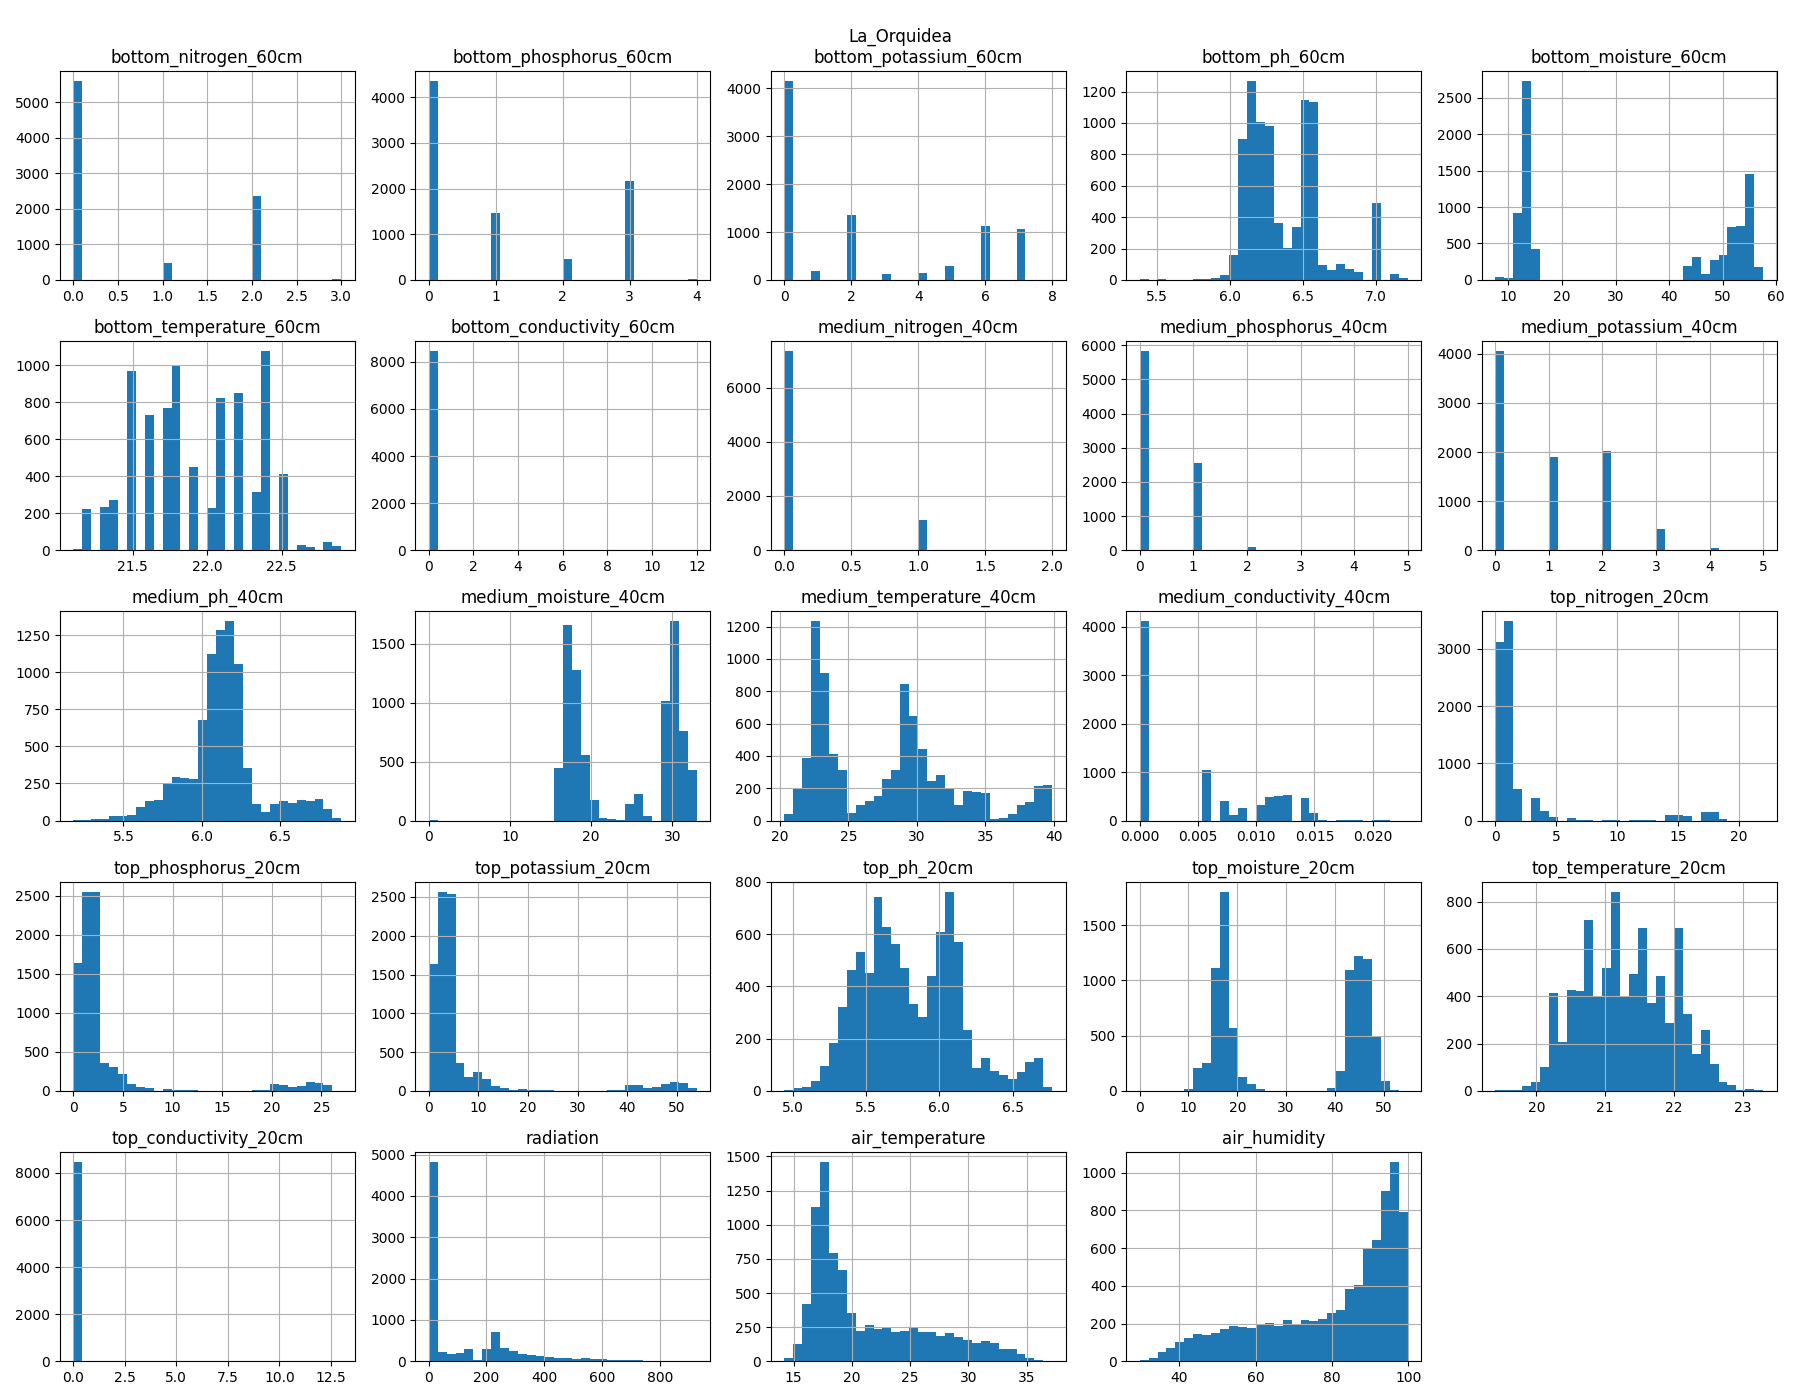

## Venecia 

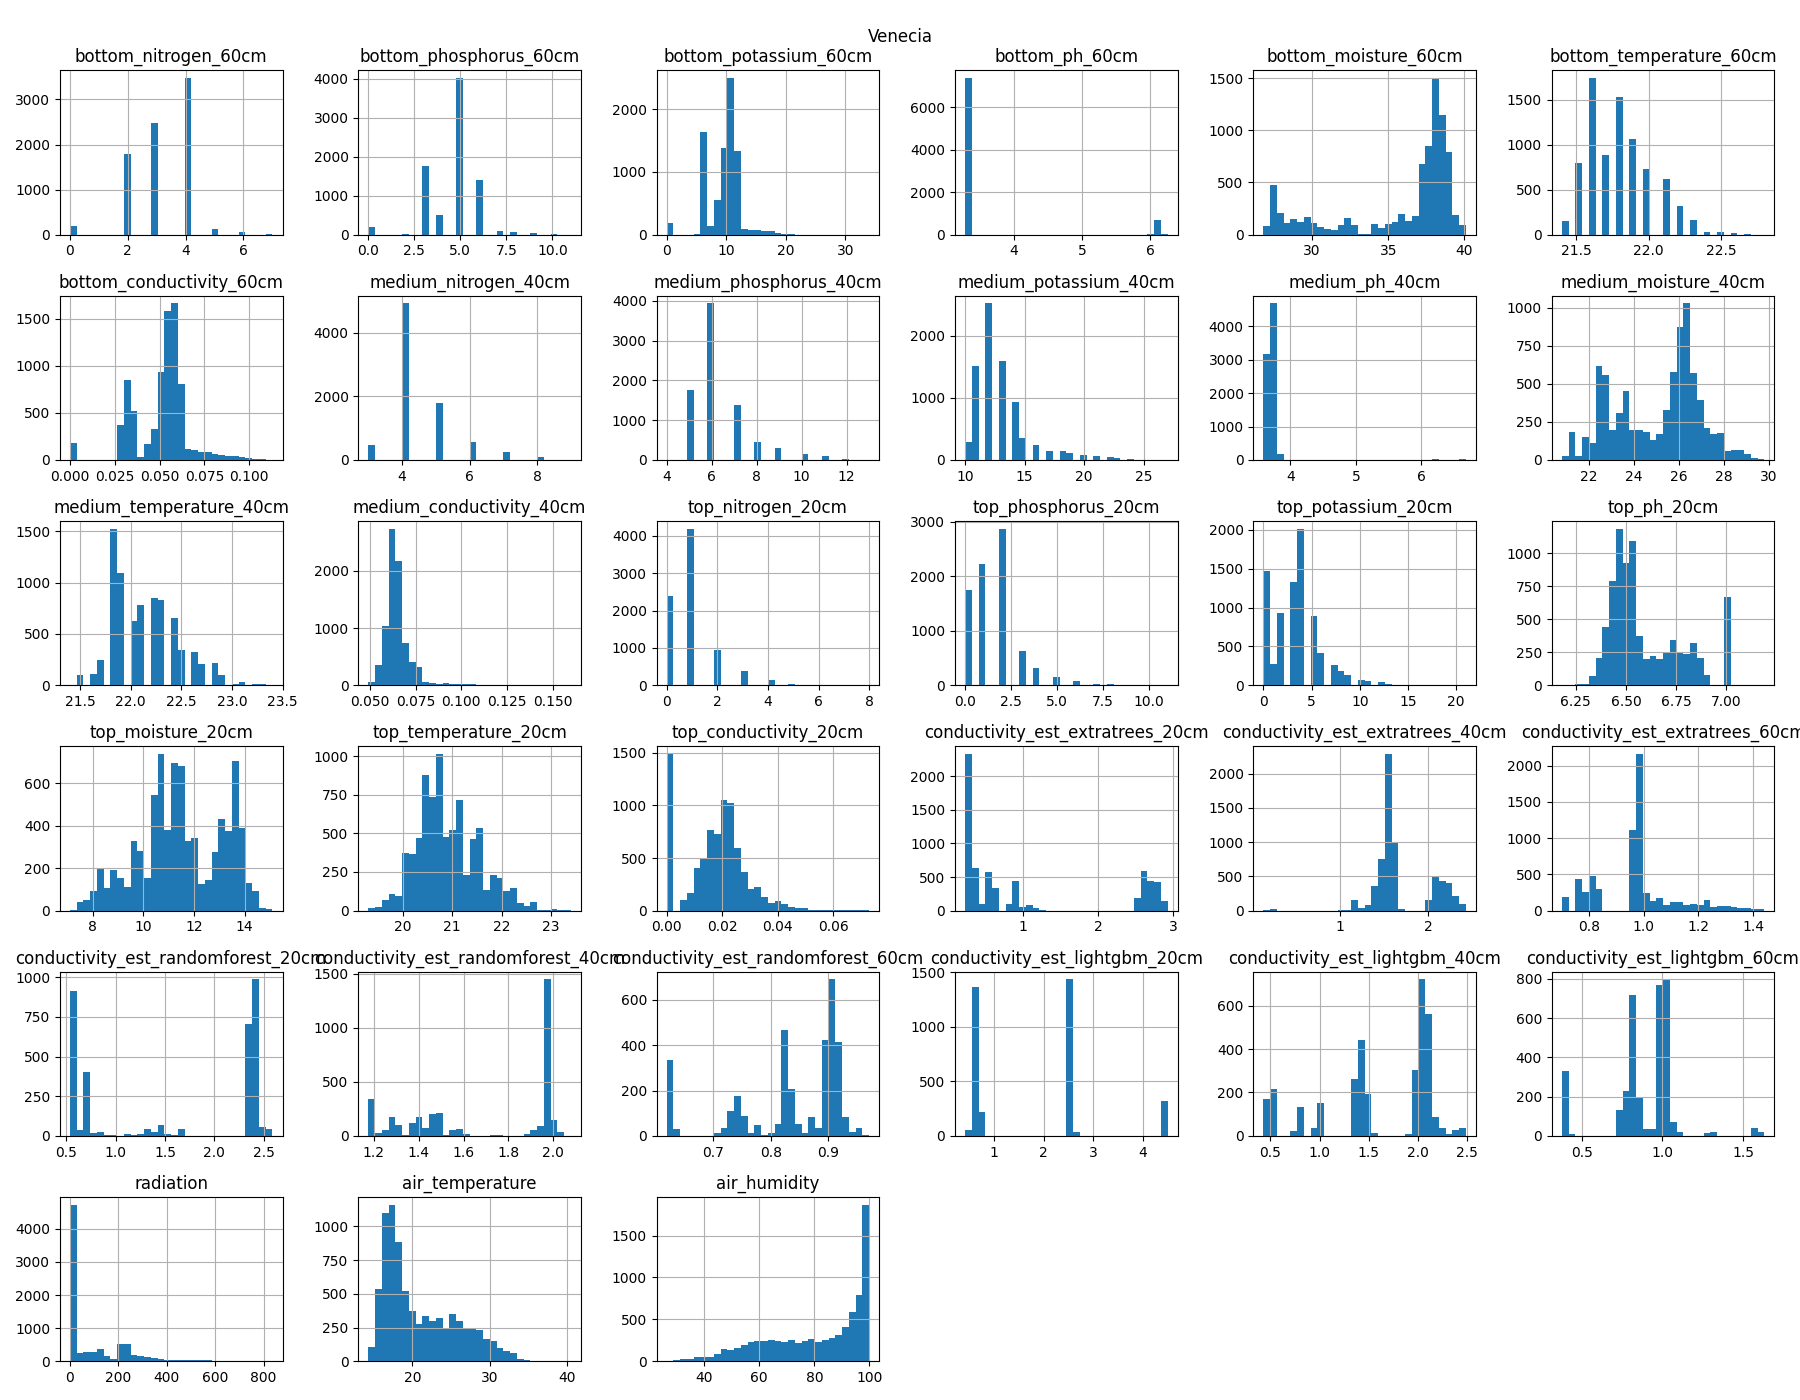

## Puerto_Arturo 

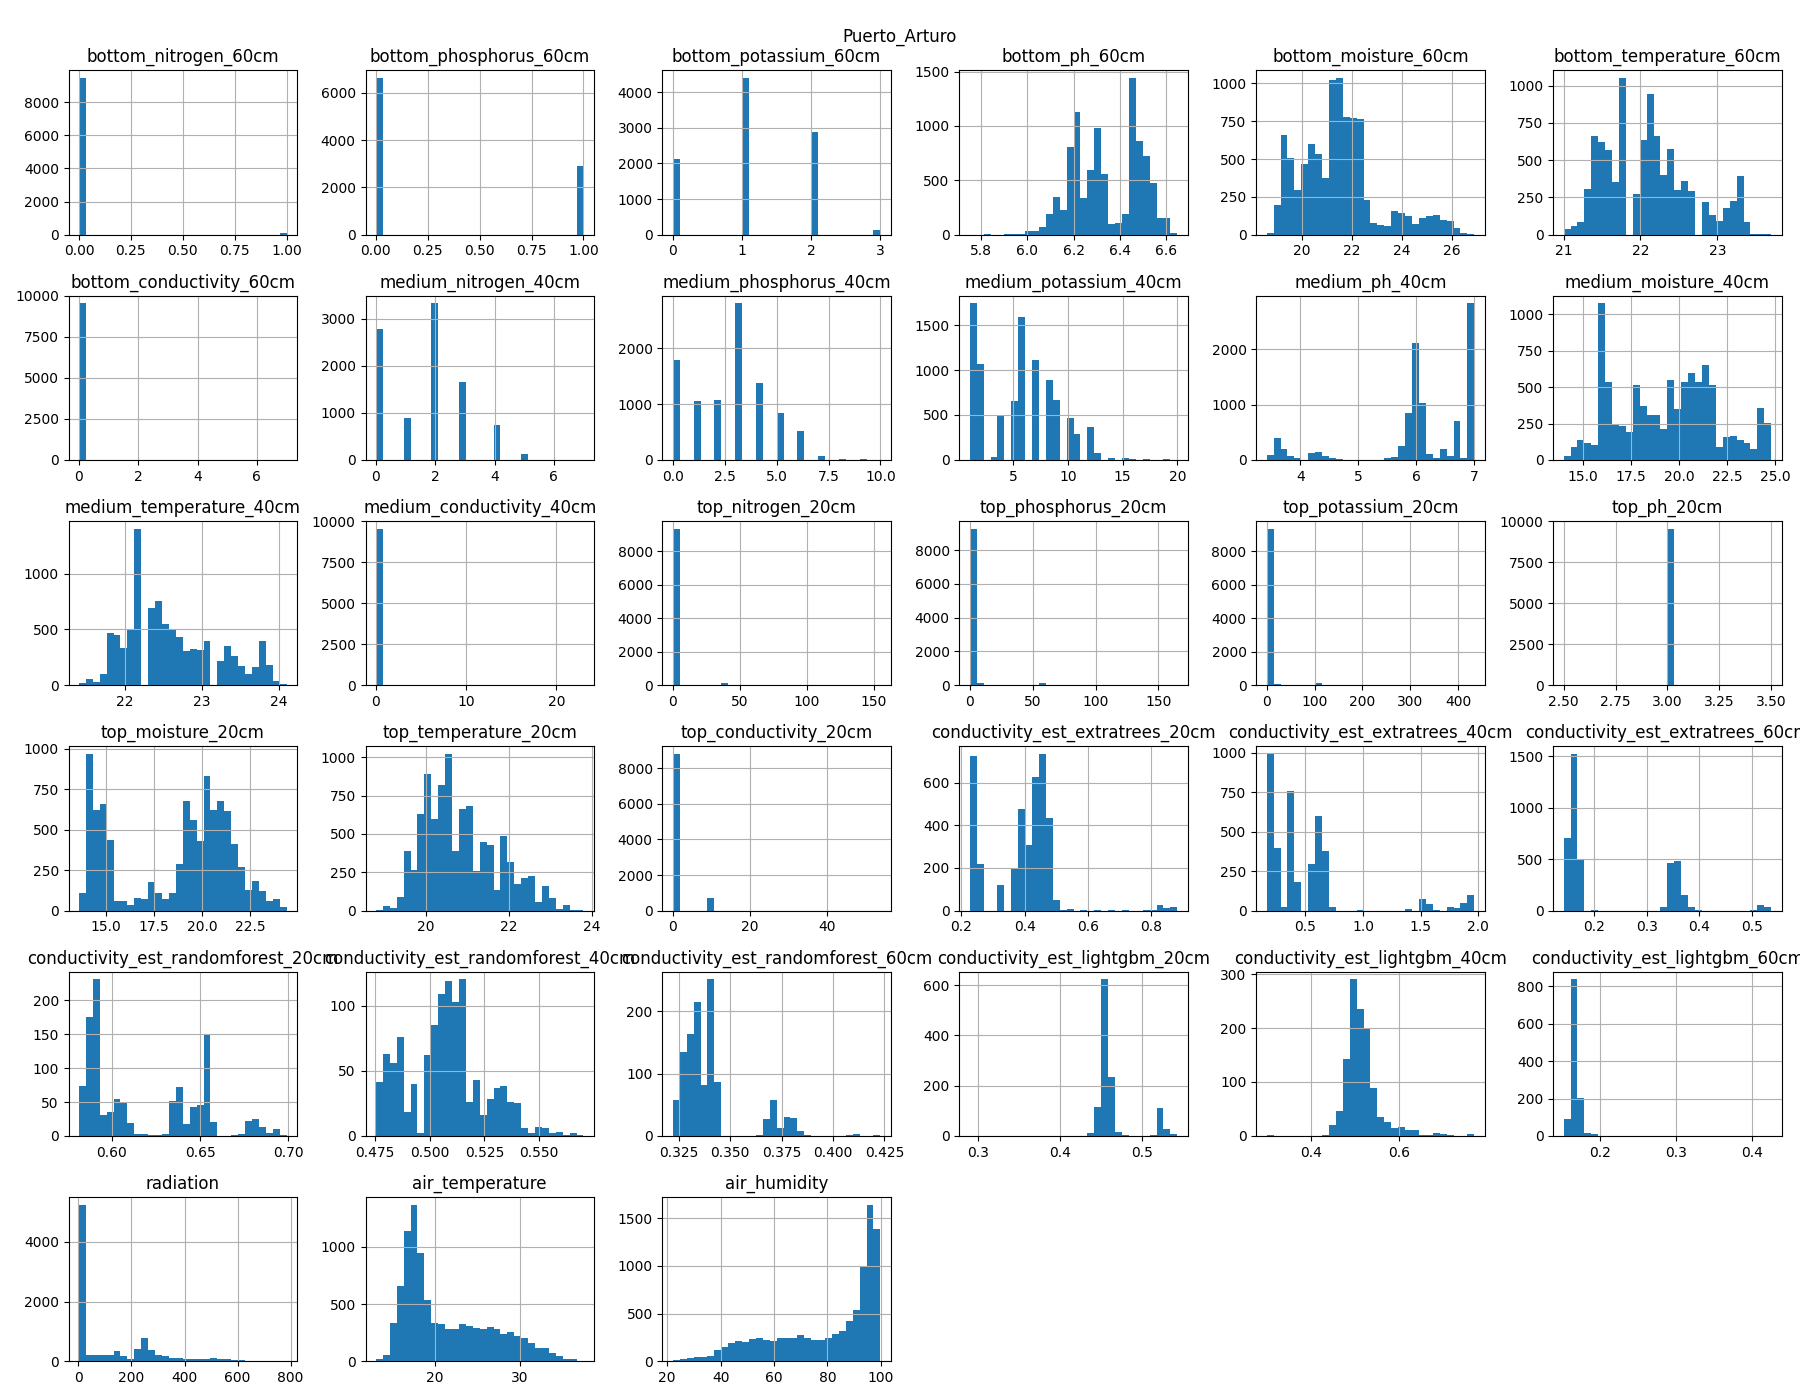

In [41]:
plt.close("all")  # cierra las figuras que dejó abierto el widget anterior
for finca, df in BD_FIJA_FILTERED.items():
    display(Markdown(f"## {finca} "))
    df[columnas_analisis(df)].hist(bins=30, figsize=(18, 14))
    plt.suptitle(finca)
    plt.tight_layout()
    plt.show()

# FLAGS

In [31]:
# =========================================================
# ALARMAS DE CALIDAD DE DATOS (misma lógica que ProcessingModule.py)
# =========================================================
from sklearn.ensemble import IsolationForest

COLUMNAS_REPORTE = ["Fecha", "Variable", "Valor", "Flag", "Alarma", "Detalle"]
COLORES_FLAGS = {1: "#D55E00", 2: "#066806", 3: "#CC0773",
                 4: "#0331CA", 5: "#00EEFF", 6: "#000000"}


# =========================================================
# 0. FUNCIONES AUXILIARES DEL REPORTE
# =========================================================

def agregar_alarmas(reporte: list, mask: pd.Series, variable: str, valores: pd.Series,
                    flag: int, detalle) -> list:
    """Agrega al reporte una fila por cada dato marcado en `mask`.

    Args:
        reporte (list): Lista de DataFrames con las alarmas acumuladas.
        mask (pd.Series): True en los registros con alarma (índice temporal).
        variable (str): Nombre de la variable (o "Multivariable").
        valores (pd.Series): Valor que se guarda en la columna "Valor".
        flag (int): Código de la alarma (clave de FLAGS).
        detalle (str | pd.Series): Texto que explica la alarma (uno fijo o uno por registro).

    Returns:
        list: El mismo reporte con las nuevas filas.
    """
    if not mask.any():
        return reporte

    reporte.append(pd.DataFrame({
        "Fecha": mask.index[mask],
        "Variable": variable,
        "Valor": valores[mask].to_numpy(),
        "Flag": flag,
        "Alarma": FLAGS[flag],
        "Detalle": detalle[mask].to_numpy() if isinstance(detalle, pd.Series) else detalle,
    }))
    return reporte


def consolidar_reporte(reporte: list) -> pd.DataFrame:
    """Une la lista de alarmas en un solo DataFrame.

    Args:
        reporte (list): Lista de DataFrames con alarmas.

    Returns:
        pd.DataFrame: Alarmas unidas (vacío con las columnas del reporte si no hay alarmas).
    """
    if reporte:
        return pd.concat(reporte, ignore_index=True)
    return pd.DataFrame(columns=COLUMNAS_REPORTE)


# =========================================================
# 1. VALIDACION DE RANGOS (flag 1: física, flag 2: histórica)
# =========================================================

def validar_rangos(df: pd.DataFrame, variable_map: dict, valid_ranges: dict,
                   lower_percentile: float = 1, upper_percentile: float = 99) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Marca valores fuera del rango físico del sensor y fuera de los percentiles históricos.

    Args:
        df (pd.DataFrame): Telemetría de UNA finca con índice temporal.
        variable_map (dict): {columna: tipo de variable}, p. ej. variables_mapping.
        valid_ranges (dict): {tipo de variable: (mínimo, máximo)} físicos.
        lower_percentile (float): Percentil inferior histórico.
        upper_percentile (float): Percentil superior histórico.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: df con columnas `<variable>_flag` y reporte de alarmas.
    """
    df = df.copy()
    reporte = []

    for column, variable in variable_map.items():
        if column not in df.columns:
            continue
        df[f"{column}_flag"] = 0
        minimo, maximo = valid_ranges[variable]

        # 1. Anomalía física: fuera de lo que el sensor puede medir
        mask_fisica = df[column].notna() & ((df[column] < minimo) | (df[column] > maximo))
        df.loc[mask_fisica, f"{column}_flag"] = 1
        reporte = agregar_alarmas(reporte, mask_fisica, column, df[column], flag=1,
                                  detalle=f"Fuera del rango físico [{minimo}, {maximo}]")

        # 2. Anomalía histórica: fuera de P1-P99 de los datos válidos de la finca
        datos_validos = df.loc[df[f"{column}_flag"] == 0, column].dropna()
        if datos_validos.empty:
            continue
        q_low = datos_validos.quantile(lower_percentile / 100)
        q_high = datos_validos.quantile(upper_percentile / 100)

        mask_hist = (df[f"{column}_flag"] == 0) & df[column].notna() & \
                    ((df[column] < q_low) | (df[column] > q_high))
        df.loc[mask_hist, f"{column}_flag"] = 2
        reporte = agregar_alarmas(reporte, mask_hist, column, df[column], flag=2,
                                  detalle=f"Fuera de P{lower_percentile}-P{upper_percentile} "
                                          f"[{q_low:.2f}, {q_high:.2f}]")

    return df, consolidar_reporte(reporte)


# =========================================================
# 2. DETECCION DE PICOS Y VALLES (flag 3: spike aislado)
# =========================================================

def detectar_spikes(df: pd.DataFrame, variable_map: dict, max_change: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Marca un dato que salta respecto a sus dos vecinos mientras los vecinos son parecidos entre sí.

    Args:
        df (pd.DataFrame): Salida de `validar_rangos` (con columnas `_flag`).
        variable_map (dict): {columna: tipo de variable}.
        max_change (dict): {tipo de variable: cambio máximo permitido entre registros}.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: df con flags actualizados y reporte de alarmas.
    """
    df = df.copy()
    reporte = []

    for column, variable in variable_map.items():
        if f"{column}_flag" not in df.columns:
            continue
        threshold = max_change[variable]

        prev = df[column].shift(1)
        curr = df[column]
        nxt = df[column].shift(-1)

        delta_prev = (curr - prev).abs()
        delta_next = (nxt - curr).abs()
        delta_neighbors = (nxt - prev).abs()

        mask = ((df[f"{column}_flag"] == 0) & prev.notna() & curr.notna() & nxt.notna() &
                (delta_prev > threshold) & (delta_next > threshold) & (delta_neighbors <= threshold))

        df.loc[mask, f"{column}_flag"] = 3
        detalle = ("Salto de " + delta_prev.round(2).astype(str) + " y " +
                   delta_next.round(2).astype(str) + f" respecto a vecinos (umbral {threshold})")
        reporte = agregar_alarmas(reporte, mask, column, df[column], flag=3, detalle=detalle)

    return df, consolidar_reporte(reporte)


# =========================================================
# 3. VALIDACION DE CAMBIO TEMPORAL (flag 4: cambio brusco)
# =========================================================

def validar_cambio_brusco(df: pd.DataFrame, variable_map: dict, max_change: dict) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Marca datos cuyo cambio respecto al registro anterior supera el umbral.

    Args:
        df (pd.DataFrame): Salida de `detectar_spikes`.
        variable_map (dict): {columna: tipo de variable}.
        max_change (dict): {tipo de variable: cambio máximo permitido entre registros}.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: df con flags actualizados y reporte de alarmas.
    """
    df = df.copy()
    reporte = []

    for column, variable in variable_map.items():
        if f"{column}_flag" not in df.columns:
            continue
        threshold = max_change[variable]
        delta = df[column].diff().abs()

        mask = (df[f"{column}_flag"] == 0) & df[column].notna() & (delta > threshold)

        df.loc[mask, f"{column}_flag"] = 4
        detalle = "Cambio de " + delta.round(2).astype(str) + f" (umbral {threshold})"
        reporte = agregar_alarmas(reporte, mask, column, df[column], flag=4, detalle=detalle)

    return df, consolidar_reporte(reporte)


# =========================================================
# 4. OUTLIERS LOCALES - ROLLING MAD (flag 5)
# =========================================================

def validar_outliers_mad(df: pd.DataFrame, variable_map: dict,
                         window: int = 48, threshold: float = 4) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Marca datos alejados de la mediana móvil según un z-score robusto (MAD).

    Args:
        df (pd.DataFrame): Salida de `validar_cambio_brusco`.
        variable_map (dict): {columna: tipo de variable}.
        window (int): Tamaño de la ventana móvil en registros (48 = ~24 h con datos cada 30 min).
        threshold (float): Z-score robusto a partir del cual se marca la alarma.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: df con flags actualizados y reporte de alarmas.
    """
    df = df.copy()
    reporte = []

    for column in variable_map:
        if f"{column}_flag" not in df.columns:
            continue

        # Excluir errores claros (físicos y spikes) del cálculo
        serie = df[column].where(~df[f"{column}_flag"].isin([1, 3]))

        rolling_median = serie.rolling(window, center=True, min_periods=window // 2).median()
        rolling_mad = (serie - rolling_median).abs().rolling(
            window, center=True, min_periods=window // 2).median()

        rolling_mad = rolling_mad.where(rolling_mad > 1e-9)   # MAD = 0 (p. ej. radiación de noche) no se evalúa
        robust_score = (serie - rolling_median).abs() / (1.4826 * rolling_mad)

        mask = df[column].notna() & (df[f"{column}_flag"] == 0) & (robust_score > threshold)

        df.loc[mask, f"{column}_flag"] = 5
        detalle = "Z-score robusto " + robust_score.round(1).astype(str) + f" (umbral {threshold})"
        reporte = agregar_alarmas(reporte, mask, column, df[column], flag=5, detalle=detalle)

    return df, consolidar_reporte(reporte)


# =========================================================
# 5. ANOMALIAS MULTIVARIABLES - ISOLATION FOREST (flag 6)
# =========================================================

def detectar_anomalias_multivariables(df: pd.DataFrame, variables: list[str], contamination: float = 0.01,
                                      random_state: int = 42) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Marca registros cuya combinación de variables es atípica (Isolation Forest de la finca).

    Args:
        df (pd.DataFrame): Salida de `validar_outliers_mad`.
        variables (list[str]): Columnas que usa el modelo.
        contamination (float): Proporción esperada de registros anómalos.
        random_state (int): Semilla para resultados reproducibles.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: df con columna `multivariable_flag` y reporte de alarmas.
    """
    df = df.copy()
    df["multivariable_flag"] = 0

    X = df[variables].fillna(df[variables].median())     # Isolation Forest no acepta NaN
    model = IsolationForest(contamination=contamination, random_state=random_state,
                            n_estimators=200, n_jobs=-1).fit(X)

    score = pd.Series(model.decision_function(X), index=df.index)
    mask = pd.Series(model.predict(X) == -1, index=df.index)

    df.loc[mask, "multivariable_flag"] = 6
    detalle = "Puntaje Isolation Forest " + score.round(3).astype(str)
    reporte = agregar_alarmas([], mask, "Multivariable", score, flag=6, detalle=detalle)

    return df, consolidar_reporte(reporte)


# =========================================================
# 6. PIPELINE DE ALARMAS POR FINCA
# =========================================================

def asignar_etapa(df: pd.DataFrame, finca: str) -> pd.Series:
    """Nombre de la etapa a la que pertenece cada registro.

    Args:
        df (pd.DataFrame): Telemetría de la finca con índice temporal.
        finca (str): Nombre de la finca.

    Returns:
        pd.Series: Etapa de cada registro ("Sin etapa" si no cae en ninguna).
    """
    etapa = pd.Series("Sin etapa", index=df.index, name="Etapa")
    for nombre in obtener_rangos(FINCAS_POR_NOMBRE[finca]):
        etapa.loc[filtrar_etapa(df, finca, nombre).index] = nombre
    return etapa


def generar_alarmas_finca(df: pd.DataFrame, finca: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Aplica todas las validaciones en orden. Cada dato conserva la PRIMERA alarma que recibe.

    Args:
        df (pd.DataFrame): Telemetría de la finca con índice temporal.
        finca (str): Nombre de la finca.

    Returns:
        tuple[pd.DataFrame, pd.DataFrame]: df con columnas de flags y "Etapa", y reporte de alarmas.
    """
    variables_if = [c for c in columnas_analisis(df)
                    if not c.endswith("_pred") and not c.startswith("conductivity_est")]

    df, r1 = validar_rangos(df, variables_mapping, valid_ranges)
    df, r2 = detectar_spikes(df, variables_mapping, max_change)
    df, r3 = validar_cambio_brusco(df, variables_mapping, max_change)
    df, r4 = validar_outliers_mad(df, variables_mapping, window=48, threshold=4)
    df, r5 = detectar_anomalias_multivariables(df, variables_if)

    df["Etapa"] = asignar_etapa(df, finca)
    reporte = consolidar_reporte([r for r in (r1, r2, r3, r4, r5) if not r.empty])
    reporte.insert(0, "Finca", finca)
    reporte.insert(1, "Etapa", df["Etapa"].reindex(reporte["Fecha"]).to_numpy())
    return df, reporte.sort_values(["Fecha", "Flag"]).reset_index(drop=True)


# =========================================================
# 7. RESUMEN Y VISUALIZACION DE ALARMAS
# =========================================================

def resumen_alarmas(reporte: pd.DataFrame) -> pd.DataFrame:
    """Resume las alarmas por finca, etapa, variable y tipo, con sus fechas.

    Args:
        reporte (pd.DataFrame): Reporte de alarmas (una o varias fincas).

    Returns:
        pd.DataFrame: Cantidad de alarmas, días con alarma y primera/última fecha.
    """
    reporte = reporte.sort_values(["Finca", "Fecha"])
    return (reporte
            .groupby(["Finca", "Etapa", "Variable", "Alarma"], sort=False)
            .agg(Alarmas=("Fecha", "size"),
                 Dias_con_alarma=("Fecha", lambda f: f.dt.normalize().nunique()),
                 Primera_fecha=("Fecha", "min"),
                 Ultima_fecha=("Fecha", "max"))
            .rename(columns={"Dias_con_alarma": "Días con alarma",
                             "Primera_fecha": "Primera fecha",
                             "Ultima_fecha": "Última fecha"}))


def graficar_alarmas(df: pd.DataFrame, finca: str, variable: str, flags: list[int]) -> None:
    """Serie temporal de la variable con las alarmas marcadas por color y las etapas sombreadas.

    Args:
        df (pd.DataFrame): Salida de `generar_alarmas_finca` (puede estar recortada a una etapa).
        finca (str): Nombre de la finca.
        variable (str): Variable a graficar.
        flags (list[int]): Códigos de alarma a mostrar (1 a 6).

    Returns:
        None: Muestra la figura.
    """
    fig, ax = plt.subplots(figsize=(15, 5))
    linea = df[variable].resample("30min").mean()          # los huecos sin datos quedan en blanco
    ax.plot(linea.index, linea, color="0.65", linewidth=0.7, label="Dato")

    for flag in flags:
        columna_flag = "multivariable_flag" if flag == 6 else f"{variable}_flag"
        mask = df[columna_flag] == flag
        if mask.any():
            ax.scatter(df.index[mask], df.loc[mask, variable], s=16, zorder=3,
                       color=COLORES_FLAGS[flag], marker="x" if flag == 6 else "o",
                       label=f"{flag} - {FLAGS[flag]} ({mask.sum()})")

    for i, (etapa, tramo) in enumerate(df.groupby("Etapa", sort=False)):
        ax.axvspan(tramo.index.min(), tramo.index.max(), color=f"C{i}", alpha=0.07)
        ax.text(tramo.index.min(), 1.01 + 0.05 * (i % 2), etapa,   # alterna altura para que no se monten
                transform=ax.get_xaxis_transform(), fontsize=9)

    ax.xaxis.set_major_formatter(mdates.DateFormatter("%d/%m/%y"))
    ax.set_ylabel(variable)
    ax.set_title(f"Alarmas de {variable} - {finca}", pad=28)
    ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=9)
    plt.tight_layout()
    plt.show()


def panel_alarmas() -> None:
    """Widget: elige finca, variable, etapa y tipos de alarma; muestra gráfica y resumen.

    Args:
        None

    Returns:
        None: Muestra los widgets, la gráfica y la tabla de alarmas filtrada.
    """
    w_finca = widgets.Dropdown(options=list(FLAGS_ALARMAS), description="Finca")
    w_variable = widgets.Dropdown(description="Variable")
    w_etapa = widgets.Dropdown(description="Etapa")
    w_flags = widgets.SelectMultiple(options=[(f"{k} - {v}", k) for k, v in FLAGS.items() if 1 <= k <= 6],
                                     value=tuple(range(1, 7)), rows=6, description="Alarmas")

    def al_cambiar_finca(cambio=None):
        df = FLAGS_ALARMAS[w_finca.value]
        w_variable.options = [c for c in variables_mapping
                              if f"{c}_flag" in df.columns and df[c].notna().any()]
        w_etapa.options = ["Ciclo completo", *df["Etapa"].unique()]

    def actualizar(finca, variable, etapa, flags):
        if not variable or etapa is None:
            return
        df = FLAGS_ALARMAS[finca]
        if etapa != "Ciclo completo":
            df = df[df["Etapa"] == etapa]
        graficar_alarmas(df, finca, variable, list(flags))

        tabla = REPORTE_ALARMAS[(REPORTE_ALARMAS["Finca"] == finca) &
                                (REPORTE_ALARMAS["Variable"].isin([variable, "Multivariable"])) &
                                (REPORTE_ALARMAS["Flag"].isin(flags))]
        if etapa != "Ciclo completo":
            tabla = tabla[tabla["Etapa"] == etapa]
        display(resumen_alarmas(tabla) if not tabla.empty else Markdown("_Sin alarmas con estos filtros._"))

    al_cambiar_finca()
    w_finca.observe(al_cambiar_finca, "value")
    salida = widgets.interactive_output(actualizar, {"finca": w_finca, "variable": w_variable,
                                                     "etapa": w_etapa, "flags": w_flags})
    display(widgets.HBox([widgets.VBox([w_finca, w_variable, w_etapa]), w_flags]), salida)


# =========================================================
# 8. VALORES FALTANTES POR ETAPA
# =========================================================

def graficar_faltantes_por_etapa() -> None:
    """Barras: cuántos registros tienen 1, 2, 3, ... variables sin dato, por finca (filas) y etapa (columnas).

    Args:
        None

    Returns:
        None: Muestra la figura.
    """
    fincas = list(BD_FIJA_FILTERED)
    etapas = list(dict.fromkeys(e for f in fincas for e in obtener_rangos(FINCAS_POR_NOMBRE[f])))

    fig, axes = plt.subplots(len(fincas), len(etapas), figsize=(4 * len(etapas), 3 * len(fincas)),
                             sharex=True, squeeze=False)

    for i, finca in enumerate(fincas):
        columnas = columnas_analisis(BD_FIJA_FILTERED[finca])
        for j, etapa in enumerate(etapas):
            ax = axes[i, j]
            if etapa not in obtener_rangos(FINCAS_POR_NOMBRE[finca]):
                ax.set_visible(False)
                continue

            datos = filtrar_etapa(BD_FIJA_FILTERED[finca], finca, etapa)[columnas]
            n_faltantes = datos.isna().sum(axis=1)               # variables sin dato en cada registro
            conteo = n_faltantes[n_faltantes > 0].value_counts().sort_index()

            ax.bar(conteo.index, conteo.values, color="steelblue")
            ax.set_xlim(0.5, len(columnas) + 0.5)
            ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
            if conteo.empty:
                ax.text(0.5, 0.5, "Sin faltantes", transform=ax.transAxes, ha="center")
                ax.set_yticks([])
            ax.set_title(f"{finca} - {etapa}\n{len(datos)} registros, "
                         f"{(n_faltantes == 0).sum()} completos", fontsize=10)
            if j == 0:
                ax.set_ylabel("Registros")
            if i == len(fincas) - 1:
                ax.set_xlabel(f"Variables sin dato (de {len(columnas)})")

    plt.tight_layout()
    plt.show()

In [32]:
FLAGS_ALARMAS = {}      # {finca: DataFrame con columnas <variable>_flag, multivariable_flag y Etapa}
REPORTES = {}           # {finca: reporte detallado de alarmas}
for finca, df in BD_FIJA_FILTERED.items():
    FLAGS_ALARMAS[finca], REPORTES[finca] = generar_alarmas_finca(df, finca)

REPORTE_ALARMAS = pd.concat(REPORTES.values(), ignore_index=True)
REPORTE_ALARMAS.head(20)

,Finca,Etapa,Fecha,Variable,Valor,Flag,Alarma,Detalle
0,La_Orquidea,Pre-siembra,2025-11-24 00:07:32,bottom_moisture_60cm,57.300,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
1,La_Orquidea,Pre-siembra,2025-11-24 00:37:20,bottom_moisture_60cm,57.500,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
2,La_Orquidea,Pre-siembra,2025-11-24 01:07:03,bottom_moisture_60cm,57.300,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
3,La_Orquidea,Pre-siembra,2025-11-24 01:36:45,bottom_moisture_60cm,57.400,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
4,La_Orquidea,Pre-siembra,2025-11-24 02:06:28,bottom_moisture_60cm,57.400,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
5,La_Orquidea,Pre-siembra,2025-11-24 02:36:12,bottom_moisture_60cm,57.400,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
6,La_Orquidea,Pre-siembra,2025-11-24 03:06:56,bottom_moisture_60cm,57.600,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
7,La_Orquidea,Pre-siembra,2025-11-24 03:36:41,bottom_moisture_60cm,57.400,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"
8,La_Orquidea,Pre-siembra,2025-11-24 03:36:41,medium_ph_40cm,5.850,5,Outlier MAD,Z-score robusto 12.8 (umbral 4)
9,La_Orquidea,Pre-siembra,2025-11-24 04:06:23,bottom_moisture_60cm,57.300,2,Anomalía histórica,"Fuera de P1-P99 [11.00, 56.70]"


In [33]:
resumen_alarmas(REPORTES["La_Orquidea"])

Alarmas  Días con alarma       Primera fecha        Última fecha
Finca       Etapa       Variable                 Alarma                                                                              
La_Orquidea Pre-siembra bottom_moisture_60cm     Anomalía histórica       83                3 2025-11-24 00:07:32 2025-11-26 02:42:55
                        medium_ph_40cm           Outlier MAD              52               12 2025-11-24 03:36:41 2025-12-08 12:43:50
                        bottom_ph_60cm           Anomalía histórica       19                6 2025-11-24 04:36:07 2025-12-06 11:10:19
                        bottom_conductivity_60cm Outlier MAD              16               12 2025-11-24 07:05:46 2025-12-07 16:04:48
                        radiation                Outlier MAD               5                1 2025-11-24 11:33:56 2025-11-24 14:14:24
...                                                                      ...              ...                 ...                 ...
            Cosecha     air_humidity             Cambio brusco             2                2 2026-04-26 18:35:33 2026-05-13 14:36:41
                        bottom_temperature_60cm  Anomalía histórica       82                4 2026-04-28 14:31:06 2026-05-20 23:57:13
                        bottom_ph_60cm           Spike aislado             1                1 2026-04-28 14:49:32 2026-04-28 14:49:32
                        top_temperature_20cm     Outlier MAD               4                1 2026-04-29 07:11:39 2026-04-29 07:44:36
                        medium_conductivity_40cm Outlier MAD               1                1 2026-05-01 19:51:15 2026-05-01 19:51:15

[136 rows x 4 columns]

In [34]:
resumen_alarmas(REPORTES["Venecia"])

Alarmas  Días con alarma       Primera fecha        Última fecha
Finca   Etapa       Variable                 Alarma                                                                                  
Venecia Pre-siembra top_conductivity_20cm    Anomalía histórica           25                9 2026-05-05 00:21:32 2026-05-20 12:49:22
                    medium_moisture_40cm     Anomalía histórica           26                2 2026-05-05 00:21:32 2026-05-06 00:59:56
                    bottom_moisture_60cm     Anomalía histórica           29                2 2026-05-05 00:21:32 2026-05-06 11:32:50
                    bottom_ph_60cm           Anomalía histórica           63               13 2026-05-05 01:52:22 2026-05-19 22:08:41
                    medium_conductivity_40cm Anomalía histórica            5                3 2026-05-05 04:53:04 2026-05-20 15:51:59
...                                                                      ...              ...                 ...                 ...
        Cosecha     bottom_moisture_60cm     Anomalía histórica           47                7 2026-10-05 20:28:50 2026-10-18 10:11:49
                    bottom_temperature_60cm  Outlier MAD                   2                2 2026-10-07 23:48:44 2026-10-08 00:18:35
                    radiation                Anomalía histórica            1                1 2026-10-14 11:40:47 2026-10-14 11:40:47
                    medium_moisture_40cm     Anomalía histórica           27                4 2026-10-15 08:38:06 2026-10-18 22:39:06
                    Multivariable            Anomalía multivariable       74                4 2026-10-15 08:38:06 2026-10-18 23:09:50

[113 rows x 4 columns]

In [35]:
resumen_alarmas(REPORTES["Puerto_Arturo"])

Alarmas  Días con alarma       Primera fecha        Última fecha
Finca         Etapa       Variable                Alarma                                                                                  
Puerto_Arturo Pre-siembra top_moisture_20cm       Anomalía histórica           16                1 2026-02-06 00:11:39 2026-02-06 19:05:24
                          medium_moisture_40cm    Anomalía histórica           88                4 2026-02-06 00:11:39 2026-02-09 22:01:44
                          bottom_ph_60cm          Outlier MAD                  10                4 2026-02-06 04:10:30 2026-02-09 11:32:35
                          medium_ph_40cm          Outlier MAD                  10                3 2026-02-06 09:15:22 2026-02-09 11:32:35
                          radiation               Outlier MAD                  67                4 2026-02-06 10:32:45 2026-02-09 17:32:20
...                                                                           ...              ...                 ...                 ...
              Cosecha     bottom_temperature_60cm Anomalía histórica           88               11 2026-08-11 02:55:44 2026-08-30 12:17:19
                          top_conductivity_20cm   Anomalía física             735               18 2026-08-14 07:05:23 2026-08-31 23:38:49
                          Multivariable           Anomalía multivariable       92               16 2026-08-14 08:05:52 2026-08-31 17:38:37
                          top_conductivity_20cm   Spike aislado                81               18 2026-08-14 13:34:36 2026-08-31 20:38:46
                                                  Cambio brusco                21               14 2026-08-15 20:11:15 2026-08-31 01:15:04

[113 rows x 4 columns]

In [36]:
panel_alarmas()

Output()

## Missings

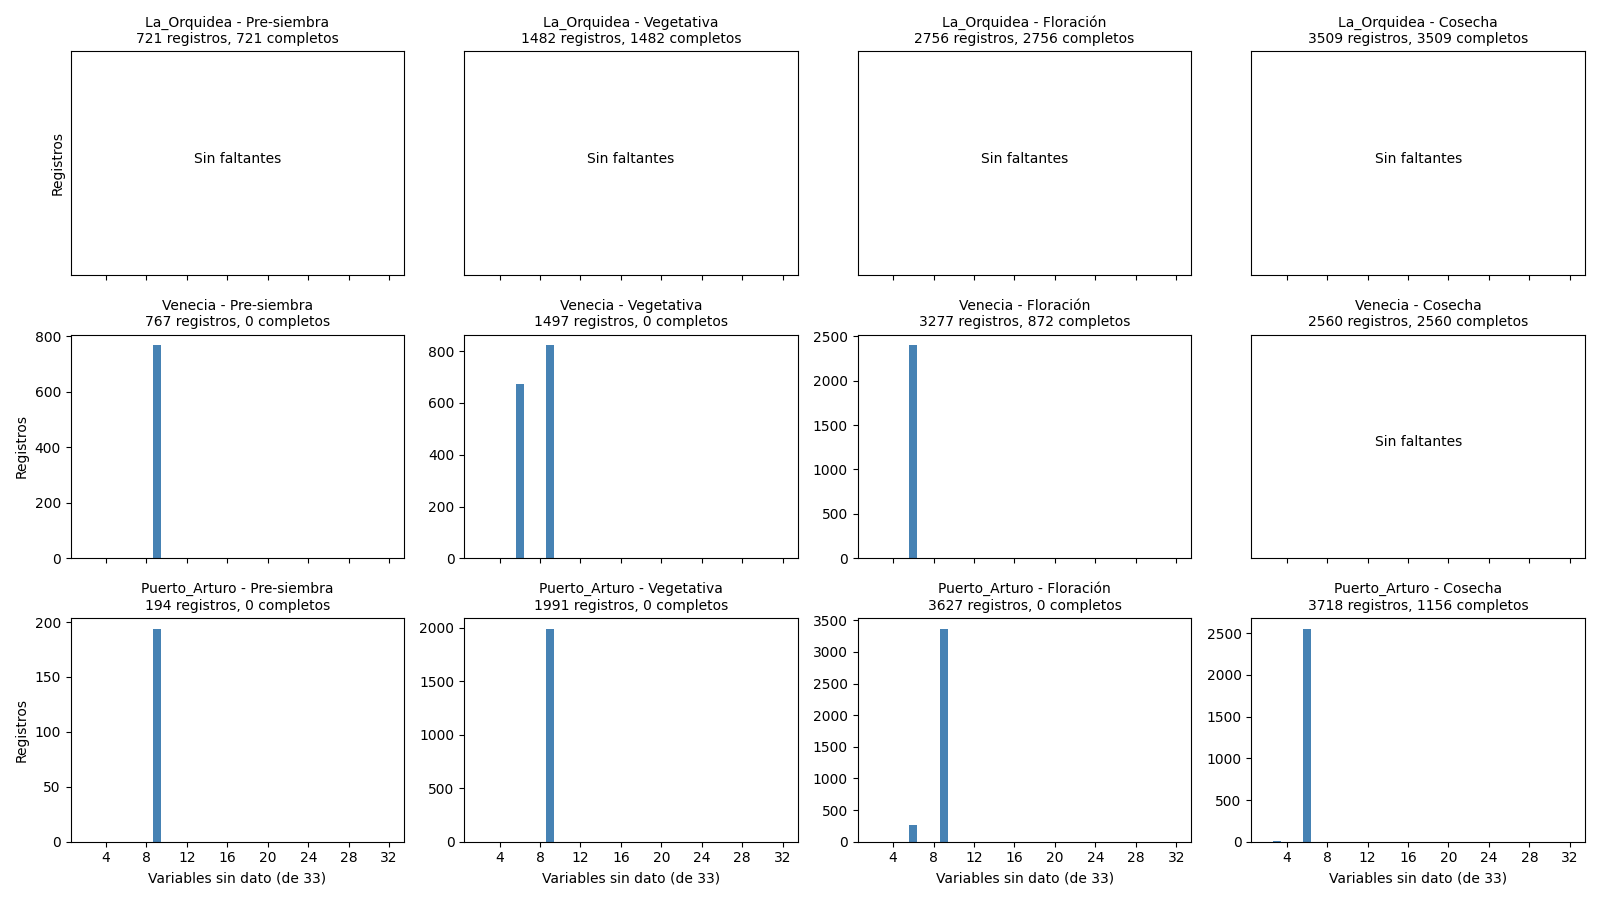

In [48]:
graficar_faltantes_por_etapa()